# PHÂN LOẠI RỦI RO TÍN DỤNG KHÁCH HÀNG VAY TIÊU DÙNG
## Business Data Analytics Project - HUFLIT 2026

### **1. Tên bước (Name):** Giới thiệu dự án và thiết lập môi trường.
### **2. Mục đích (Purpose):** Xây dựng mô hình học máy phân loại rủi ro tín dụng của khách hàng vay tiêu dùng dựa trên dữ liệu Lending Club, hỗ trợ ra quyết định duyệt tín dụng tự động và giảm thiểu tỷ lệ nợ xấu cho ngân hàng.
### **3. Phương pháp (Method):** Áp dụng quy trình phân tích và học máy chuẩn gồm: Phân tích khám phá dữ liệu (EDA), tiền xử lý và chuẩn hóa dữ liệu, chia tập Train/Test chống leakage, huấn luyện 8 phương pháp/mô hình phân loại và xử lý mất cân bằng nhãn khác nhau (gồm Logistic Regression, Decision Tree, Random Forest, XGBoost Classifier, LDA, PCA + LR, SMOTE + LR, Undersampling + LR) và đánh giá so sánh chéo.
### **4. Phản hồi/Kết quả mong đợi (Response):** Một hệ thống phân tích hoàn chỉnh từ khâu khám phá số liệu đến huấn luyện mô hình, giúp ngân hàng nhận diện đúng khách hàng có nguy cơ vỡ nợ.

---

# 3 CÂU HỎI NGHIÊN CỨU CỐT LÕI CỦA ĐỀ TÀI (RESEARCH QUESTIONS)

Để giải quyết triệt để bài toán kinh doanh và kỹ thuật phê duyệt tín dụng, đồ án tập trung trả lời 3 câu hỏi nghiên cứu sau:
1. **Câu hỏi 1 (Khảo sát đặc trưng & Rủi ro):** Yếu tố tài chính và phi tài chính nào của người đi vay (thu nhập, tỷ lệ nợ DTI, hạng tín dụng Grade, mục đích vay) có ảnh hưởng mạnh nhất đến xác suất trễ hạn hoặc vỡ nợ của họ?
2. **Câu hỏi 2 (Kỹ thuật mô hình & Lệch nhãn):** Làm thế nào để xây dựng mô hình học máy tối ưu có khả năng nhận diện chính xác nợ xấu trong điều kiện dữ liệu bị mất cân bằng nghiêm trọng (lệch nhãn), và kỹ thuật cân bằng dữ liệu nào mang lại hiệu quả tốt nhất?
3. **Câu hỏi 3 (Giá trị thực tiễn & Đề xuất chính sách):** Dựa trên kết quả dự báo của mô hình học máy tối ưu, ngân hàng/tổ chức tài chính nên đưa ra các quyết định phê duyệt và chính sách định giá rủi ro thực tế như thế nào để giảm thiểu tỷ lệ nợ xấu và tối ưu hóa doanh thu?


# Import Libraries

* **Tên bước (Name):** Thiết lập môi trường và nạp các thư viện Python.
* **Mục đích (Purpose):** Khởi tạo đầy đủ các công cụ cần thiết cho xử lý dữ liệu, trực quan hóa biểu đồ, xây dựng mô hình và đánh giá hiệu năng.
* **Phương pháp (Method):** Sử dụng các thư viện chuẩn của Python: `pandas`, `numpy` để xử lý dữ liệu; `matplotlib.pyplot`, `seaborn` cho biểu đồ; `sklearn` cho tiền xử lý và mô hình cơ bản; `xgboost` cho mô hình học máy nâng cao.
* **Phản hồi mong đợi (Expected Outcome):** Tất cả thư viện được nạp thành công mà không gặp lỗi hệ thống.


In [ ]:
# ==========================================
# Import Libraries
# ==========================================

# ==========================
# 1. Thư viện xử lý dữ liệu
# ==========================

import pandas as pd
import numpy as np

# ==========================
# 2. Thư viện trực quan hóa
# ==========================

import matplotlib.pyplot as plt
import seaborn as sns

# Hiển thị biểu đồ đẹp hơn
sns.set_style("whitegrid")

# ==========================
# 3. Thư viện tiền xử lý dữ liệu
# ==========================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

# ==========================
# 4. Các mô hình Machine Learning
# ==========================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ==========================
# 5. Đánh giá mô hình
# ==========================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ==========================
# 6. Cross Validation
# ==========================

from sklearn.model_selection import cross_val_score

print("="*50)
print("✅ Đã import thành công tất cả thư viện.")
print("="*50)

✅ Đã import thành công tất cả thư viện.


# Load Dataset

* **Tên bước (Name):** Đọc dữ liệu Lending Club từ Google Drive.
* **Mục đích (Purpose):** Nạp tập dữ liệu thô `loan.csv` vào dataframe của Pandas để bắt đầu phân tích.
* **Phương pháp (Method):** Sử dụng hàm `pd.read_csv` của Pandas với chế độ `low_memory=False` để tối ưu hóa bộ nhớ cho tệp tin dung lượng lớn.
* **Phản hồi mong đợi (Expected Outcome):** Đọc thành công dữ liệu và in ra kích thước của bộ dữ liệu gốc (2,260,668 dòng và 145 cột).


### Kết nối Google Drive và đọc dữ liệu


In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np

# Kết nối Google Drive
drive.mount('/content/drive')

# Đường dẫn đến dataset
file_path = "/content/drive/MyDrive/loan.csv"

# Đọc dữ liệu
df = pd.read_csv(file_path, low_memory=False)

print("="*60)
print("✅ Đọc dữ liệu thành công!")
print(f"Số dòng: {df.shape[0]:,}")
print(f"Số cột : {df.shape[1]}")
print("="*60)


Mounted at /content/drive
✅ Đọc dữ liệu thành công!
Số dòng: 2,260,668
Số cột : 145


# A. EDA & Visualization

# A1. Descriptive Statistics (0.5 điểm)

* **Tên bước (Name):** Phân tích thống kê mô tả đặc trưng số.
* **Mục đích (Purpose):** Hiểu rõ phân phối của các biến số trong dữ liệu thô thông qua các chỉ số thống kê đặc trưng như Trung bình (Mean), Trung vị (Median), Độ lệch chuẩn (Std), Độ nhọn (Kurtosis), và Độ lệch (Skewness).
* **Phương pháp (Method):** Sử dụng các hàm thống kê mô tả của Pandas (`count`, `mean`, `median`, `std`, `min`, `max`, `skew`, `kurt`) trên các cột định lượng.
* **Phản hồi mong đợi (Expected Outcome):** Bảng tổng hợp thống kê hiển thị chi tiết các chỉ số của 109 cột số trong tập dữ liệu.


In [ ]:
# Chỉ lấy các biến số
numerical_df = df.select_dtypes(include=['number'])

# Tạo bảng thống kê mô tả
descriptive_statistics = pd.DataFrame({
    'Count': numerical_df.count(),
    'Mean': numerical_df.mean(),
    'Median': numerical_df.median(),
    'Std': numerical_df.std(),
    'Min': numerical_df.min(),
    'Max': numerical_df.max(),
    'Skewness': numerical_df.skew(),
    'Kurtosis': numerical_df.kurt()
})

# Làm tròn 2 chữ số
descriptive_statistics = descriptive_statistics.round(2)

print("="*80)
print("DESCRIPTIVE STATISTICS OF NUMERICAL FEATURES")
print("="*80)

display(descriptive_statistics)

DESCRIPTIVE STATISTICS OF NUMERICAL FEATURES


,Count,Mean,Median,Std,Min,Max,Skewness,Kurtosis
id,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
member_id,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,2260668,15046.93,12900.00,9190.25,500.00,40000.00,0.78,-0.12
funded_amnt,2260668,15041.66,12875.00,9188.41,500.00,40000.00,0.78,-0.12
funded_amnt_inv,2260668,15023.44,12800.00,9192.33,0.00,40000.00,0.78,-0.12
...,...,...,...,...,...,...,...,...
hardship_payoff_balance_amount,10613,11628.04,10044.22,7615.16,55.73,40306.41,0.87,0.21
hardship_last_payment_amount,10613,193.61,132.89,198.69,0.01,1407.86,1.62,3.21
settlement_amount,33056,5030.61,4172.85,3692.03,44.21,33601.00,1.31,2.17
settlement_percentage,33056,47.78,45.00,7.34,0.20,521.35,9.32,534.18


### Thống kê mô tả các biến số tài chính quan trọng đối với rủi ro tín dụng
* **Tên bước (Name):** Thống kê mô tả các biến tài chính cốt lõi.
* **Mục đích (Purpose):** Đánh giá sơ bộ các thuộc tính tài chính có độ biến thiên cao hoặc phân phối lệch chuẩn để chuẩn bị cho các bước làm sạch dữ liệu.
* **Phương pháp (Method):** Lọc ra 10 biến số cốt lõi (`loan_amnt`, `int_rate`, `annual_inc`, `dti`, v.v.) và hiển thị các chỉ số thống kê mô tả của chúng.
* **Phản hồi mong đợi (Expected Outcome):** Bảng thống kê mô tả thu gọn hiển thị các thuộc tính tài chính quan trọng của khách hàng.


In [ ]:
# Các biến quan trọng đối với bài toán dự đoán rủi ro vay tiêu dùng

selected_features = [

    "loan_amnt",          # Số tiền vay
    "funded_amnt",        # Số tiền được giải ngân
    "int_rate",           # Lãi suất
    "installment",        # Khoản trả hàng tháng

    "annual_inc",         # Thu nhập năm
    "dti",                # Tỷ lệ nợ / thu nhập

    "revol_bal",          # Dư nợ quay vòng
    "revol_util",         # Tỷ lệ sử dụng hạn mức

    "open_acc",           # Số tài khoản tín dụng đang mở
    "total_acc"           # Tổng số tài khoản tín dụng

]

# Chỉ giữ các cột tồn tại trong dataset
selected_features = [col for col in selected_features if col in df.columns]

selected_df = df[selected_features]

# Tạo bảng thống kê

summary = pd.DataFrame({

    "Count": selected_df.count(),
    "Mean": selected_df.mean(),
    "Median": selected_df.median(),
    "Std": selected_df.std(),
    "Min": selected_df.min(),
    "Max": selected_df.max(),
    "Skewness": selected_df.skew(),
    "Kurtosis": selected_df.kurt()

})

summary = summary.round(2)

print("="*90)
print("DESCRIPTIVE STATISTICS OF IMPORTANT FEATURES")
print("="*90)

display(summary)

DESCRIPTIVE STATISTICS OF IMPORTANT FEATURES


,Count,Mean,Median,Std,Min,Max,Skewness,Kurtosis
loan_amnt,2260668,15046.93,12900.00,9190.25,500.00,4.000000e+04,0.78,-0.12
funded_amnt,2260668,15041.66,12875.00,9188.41,500.00,4.000000e+04,0.78,-0.12
int_rate,2260668,13.09,12.62,4.83,5.31,3.099000e+01,0.77,0.59
installment,2260668,445.81,377.99,267.17,4.93,1.719830e+03,1.00,0.69
annual_inc,2260664,77992.43,65000.00,112696.20,0.00,1.100000e+08,493.89,439001.66
dti,2258957,18.82,17.84,14.18,-1.00,9.990000e+02,29.20,1755.26
revol_bal,2260668,16658.46,11324.00,22948.31,0.00,2.904836e+06,13.23,643.20
revol_util,2258866,50.34,50.30,24.71,0.00,8.923000e+02,0.01,-0.22
open_acc,2260639,11.61,11.00,5.64,0.00,1.010000e+02,1.32,3.45
total_acc,2260639,24.16,22.00,11.99,1.00,1.760000e+02,1.01,1.85


### **Giải thích và đánh giá tổng quan dữ liệu từ bảng thống kê mô tả (Descriptive Statistics)**

Dựa vào các số liệu thống kê thu được từ bảng trên, nhóm có những đánh giá cụ thể về đặc điểm phân phối dữ liệu như sau:

1. **loan_amnt (Số tiền đăng ký vay):**
   - Giá trị trung bình (Mean) là **15,046.93 USD**, trong khi trung vị (Median) là **12,900 USD**. Việc trung vị nhỏ hơn trung bình cho thấy phân phối lệch phải nhẹ (Skewness = 0.78), tức là có một số khách hàng vay các khoản tiền rất lớn (lên tới mức tối đa 40,000 USD) kéo số trung bình lên.
   - Độ lệch chuẩn (Std) đạt **9,190.25 USD**, phản ánh mức độ phân tán khá lớn của các gói vay, cho thấy nhu cầu vay của khách hàng rất đa dạng.

2. **annual_inc (Thu nhập hàng năm của khách hàng):**
   - Giá trị trung bình đạt **77,992.43 USD**, nhưng trung vị chỉ là **65,000 USD**.
   - **Đặc biệt:** Hệ số lệch (Skewness) cực kỳ cao (**493.89**) và độ nhọn (Kurtosis) đạt tới **439,001.66**. Đây là số liệu chứng minh phân phối thu nhập bị lệch phải rất nặng do sự xuất hiện của những khách hàng có thu nhập đột biến (lên tới mức tối đa 110 triệu USD - Outliers). Nhóm sẽ cần áp dụng Winsorization để xử lý các giá trị cực đoan này.

3. **dti (Tỷ lệ nợ trên thu nhập):**
   - Giá trị trung vị là **17.84%** và trung bình là **18.82%**, đây là mức nợ tương đối an toàn trong hoạt động tiêu dùng (thường dưới 30%).
   - Tuy nhiên, giá trị cực đại (Max) đạt tới **999%** và Skewness = **29.20** chứng tỏ có nhiều hồ sơ có mức nợ cực kỳ báo động, đòi hỏi quy trình tiền xử lý phải làm sạch kỹ lưỡng.

4. **int_rate (Lãi suất khoản vay):**
   - Giá trị trung bình là **13.09%**, phân phối có độ lệch nhẹ (Skewness = 0.77). Khoảng lãi suất dao động từ thấp nhất **5.31%** đến cao nhất **30.99%**, phản ánh chính sách định giá dựa trên mức độ rủi ro khách hàng.

5. **revol_bal (Dư nợ quay vòng) và revol_util (Tỷ lệ sử dụng hạn mức):**
   - Dư nợ quay vòng trung bình là **16,658.46 USD** nhưng có độ lệch lớn (Skewness = 13.23) với giá trị Max lên tới hơn 2.9 triệu USD.
   - Tỷ lệ sử dụng hạn mức trung vị là **50.30%**, phản ánh khách hàng tiêu dùng sử dụng khoảng một nửa hạn mức thẻ được cấp.

**Kết luận:** Tập dữ liệu phản ánh rõ tính chất lệch phải của dữ liệu tài chính (nhiều outliers lớn về thu nhập, dư nợ). Để huấn luyện mô hình tốt, bước tiền xử lý bắt buộc phải xử lý ngoại lai (Outliers) và chuẩn hóa đặc trưng phù hợp.


# A2. Trực quan hóa dữ liệu (Data Visualization) (0.8 điểm)

Trong phần này, nhóm tiến hành xây dựng các biểu đồ trực quan hóa dữ liệu để phân tích mối quan hệ giữa các biến số và rủi ro tín dụng của khách hàng.


## Biểu đồ 1. Ma trận tương quan giữa các biến định lượng (Correlation Matrix Heatmap)
* **Tên bước (Name):** Vẽ ma trận tương quan giữa các thuộc tính định lượng chính.
* **Mục đích (Purpose):** Xác định sự tương quan tuyến tính giữa các biến số tài chính để lựa chọn đặc trưng cho mô hình và loại bỏ các đặc trưng đa cộng tuyến (Multicollinearity).
* **Phương pháp (Method):** Tính hệ số tương quan Pearson giữa 11 biến định lượng cốt lõi và trực quan hóa bằng bản đồ nhiệt Heatmap (Seaborn).
* **Phản hồi mong đợi (Expected Outcome):** Bản đồ nhiệt chỉ ra mối tương quan tuyến tính rất mạnh (> 0.90) giữa số tiền vay (`loan_amnt`), số tiền giải ngân (`funded_amnt`, `funded_amnt_inv`) và khoản trả định kỳ (`installment`).


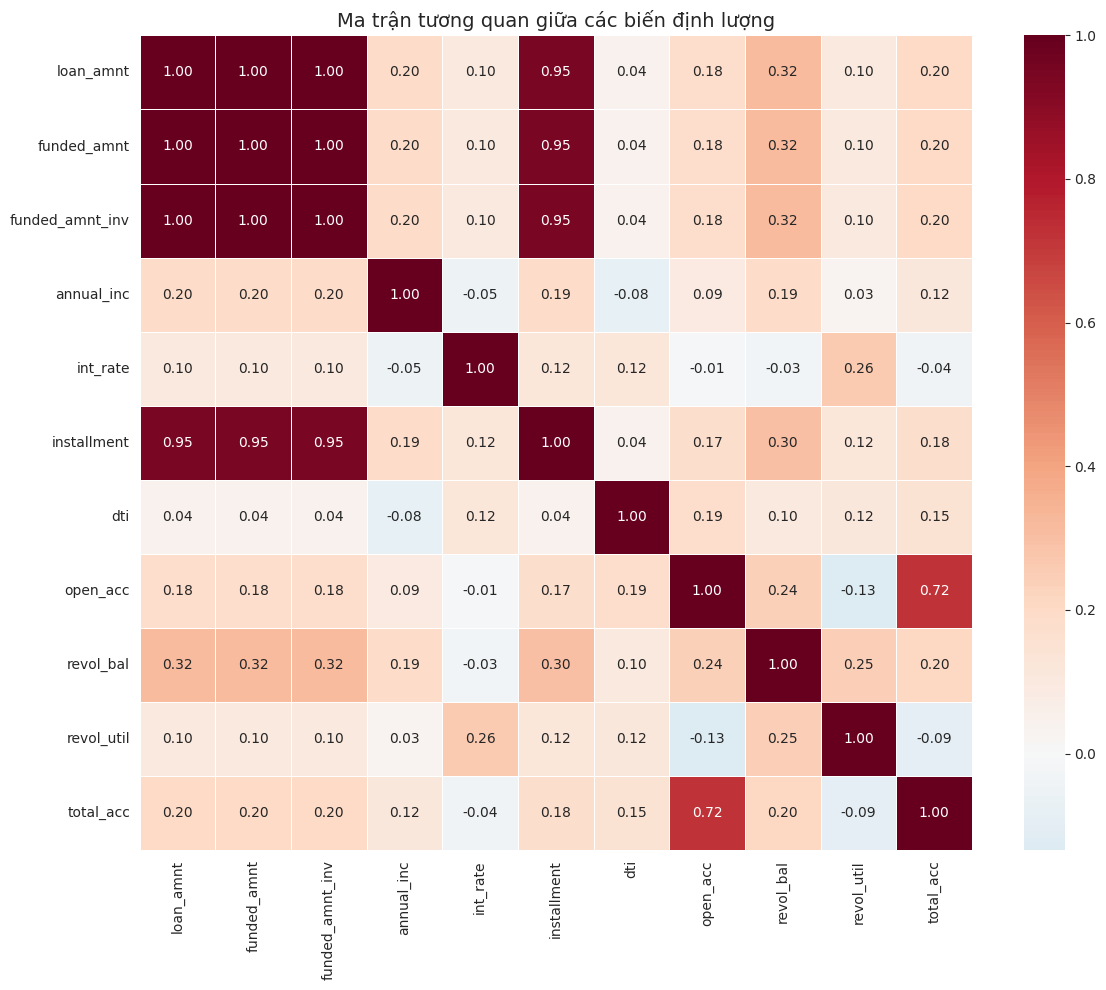

✅ Đã trực quan hóa ma trận tương quan giữa các biến định lượng.
✅ Heatmap giúp đánh giá mối quan hệ giữa các biến và hỗ trợ lựa chọn đặc trưng cho mô hình.


In [ ]:
# Chọn các biến định lượng quan trọng
corr_features = [
    "loan_amnt",
    "funded_amnt",
    "funded_amnt_inv",
    "annual_inc",
    "int_rate",
    "installment",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc"
]

# Chỉ giữ các cột thực sự tồn tại trong dataset
corr_features = [col for col in corr_features if col in df.columns]

plt.figure(figsize=(12, 10))

corr = df[corr_features].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title("Ma trận tương quan giữa các biến định lượng", fontsize=14)

plt.tight_layout()

plt.show()

print("✅ Đã trực quan hóa ma trận tương quan giữa các biến định lượng.")
print("✅ Heatmap giúp đánh giá mối quan hệ giữa các biến và hỗ trợ lựa chọn đặc trưng cho mô hình.")

### **Giải thích việc lựa chọn các biến để huấn luyện mô hình dựa trên Heatmap**

Dựa vào ma trận tương quan ở trên, ta thấy:
1. **Hiện tượng đa cộng tuyến (Multicollinearity) xuất hiện rõ rệt:**
   - Cặp biến `loan_amnt` - `funded_amnt` có hệ số tương quan tuyến tính là **1.00**.
   - Cặp biến `loan_amnt` - `funded_amnt_inv` có hệ số tương quan là **0.99**.
   - Cặp biến `loan_amnt` - `installment` có hệ số tương quan là **0.95**.
2. **Quyết định lựa chọn biến:**
   - Khi các biến có tương quan tuyến tính gần như tuyệt đối, chúng chứa thông tin trùng lặp. Đưa tất cả các biến này vào sẽ làm mất ổn định hệ số của mô hình tuyến tính (như Logistic Regression).
   - Vì vậy, nhóm quyết định **loại bỏ** `funded_amnt` và `funded_amnt_inv` để triệt tiêu đa cộng tuyến.
   - Nhóm chỉ giữ lại **`loan_amnt`** (Số tiền vay đại diện) và **`installment`** (Khoản tiền phải trả hàng tháng, mang yếu tố dòng tiền) để đưa vào huấn luyện mô hình.
3. **Các biến định lượng độc lập được giữ lại:** `int_rate`, `annual_inc`, `dti`, `revol_bal`, `revol_util`, `open_acc`, `total_acc` vì hệ số tương quan giữa chúng đều thấp (dưới 0.4), mang các thông tin độc lập hữu ích.

Dưới đây là các biểu đồ phân tích phân phối và đặc trưng của các biến được lựa chọn.


## Biểu đồ 2. Phân bố số tiền vay (Loan Amount Distribution)
* **Tên bước (Name):** Vẽ biểu đồ phân bố số tiền vay của khách hàng.
* **Mục đích (Purpose):** Quan sát xu hướng phân bố số tiền mà khách hàng đăng ký vay.
* **Phương pháp (Method):** Vẽ biểu đồ phân phối Histogram kết hợp KDE (Kernel Density Estimate) cho biến `loan_amnt`.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ cột thể hiện mật độ và phân bố số tiền vay tập trung chủ yếu ở các ngưỡng tròn trịa (như 10,000 USD, 15,000 USD, 20,000 USD).


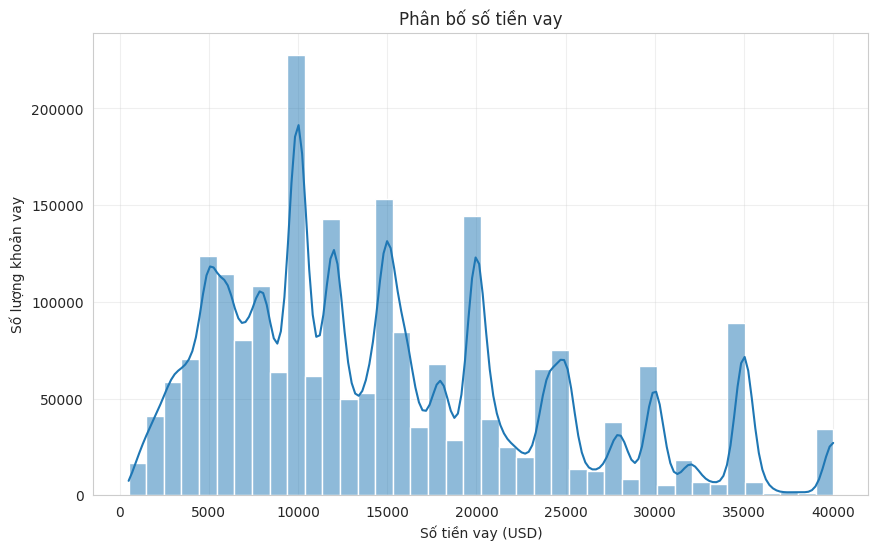

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(df["loan_amnt"], bins=40, kde=True)

plt.title("Phân bố số tiền vay")

plt.xlabel("Số tiền vay (USD)")

plt.ylabel("Số lượng khoản vay")

plt.grid(alpha=0.3)

plt.show()

### **Nhận xét**

- Số tiền vay của khách hàng tập trung nhiều nhất ở các mức tròn như **10,000 USD**, **15,000 USD**, **20,000 USD** và **35,000–40,000 USD**.

- Phân phối có xu hướng **lệch phải nhẹ (right-skewed)**, với **giá trị trung bình** khoảng **15,046.93 USD**, trong khi **trung vị** là **12,900.00 USD**.

- Việc **giá trị trung bình lớn hơn trung vị** cho thấy tồn tại một số khoản vay có giá trị lớn, kéo trung bình tăng lên.

- Kết quả này cho thấy nhu cầu vay của khách hàng khá đa dạng, tuy nhiên phần lớn vẫn tập trung ở các mức vay cố định, phản ánh xu hướng lựa chọn những khoản vay phổ biến trong hoạt động vay tiêu dùng.


## Biểu đồ 3. Phân bố thu nhập hằng năm của khách hàng (Annual Income)

- **Tên bước (Name):** Vẽ biểu đồ phân bố thu nhập hằng năm của khách hàng.

- **Mục đích (Purpose):** Phân tích đặc điểm phân bố thu nhập của khách hàng để đánh giá năng lực tài chính và khả năng chi trả khoản vay.

- **Phương pháp (Method):** Sử dụng biểu đồ Histogram để biểu diễn phân bố của biến `annual_inc`. Dữ liệu được giới hạn ở phân vị 99% (99th percentile) nhằm loại bỏ các giá trị ngoại lai quá lớn, giúp biểu đồ phản ánh chính xác hơn xu hướng của phần lớn khách hàng.

- **Phản hồi mong đợi (Expected Outcome):** Biểu đồ cho thấy thu nhập hằng năm của khách hàng tập trung chủ yếu trong khoảng **40,000 USD đến 80,000 USD**, đồng thời phân phối có xu hướng **lệch phải** do vẫn tồn tại một số khách hàng có thu nhập rất cao.


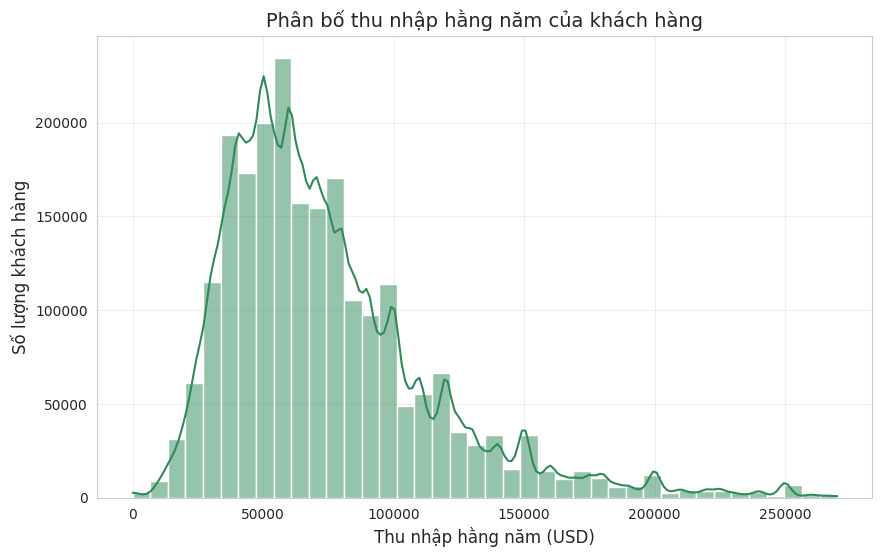

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Loại bỏ các giá trị quá lớn để biểu đồ dễ quan sát
income_plot = df[df["annual_inc"] <= df["annual_inc"].quantile(0.99)]

plt.figure(figsize=(10,6))

sns.histplot(
    data=income_plot,
    x="annual_inc",
    bins=40,
    kde=True,
    color="seagreen"
)

plt.title("Phân bố thu nhập hằng năm của khách hàng", fontsize=14)

plt.xlabel("Thu nhập hằng năm (USD)", fontsize=12)

plt.ylabel("Số lượng khách hàng", fontsize=12)

plt.grid(alpha=0.3)

plt.show()

### Nhận xét
- Thu nhập hàng năm của đa số khách hàng tập trung trong khoảng **40,000$ - 80,000$**.
- Phân phối thu nhập có độ lệch phải rất lớn (Skewness = 493.89) do sự xuất hiện của một số khách hàng có thu nhập cực kỳ cao.
- Mức thu nhập ổn định này là cơ sở quan trọng để đánh giá khả năng trả nợ của khách hàng.


## Biểu đồ 4. Phân bố tỷ lệ nợ trên thu nhập (Debt-to-Income Ratio - DTI)
* **Tên bước (Name):** Vẽ biểu đồ tỷ lệ DTI.
* **Mục đích (Purpose):** Đánh giá áp lực tài chính của khách hàng đi vay.
* **Phương pháp (Method):** Vẽ biểu đồ phân phối KDE cho biến `dti` giới hạn dưới ngưỡng 60.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ mật độ thể hiện tỷ lệ nợ trên thu nhập tập trung phổ biến quanh mức 15% - 25%.


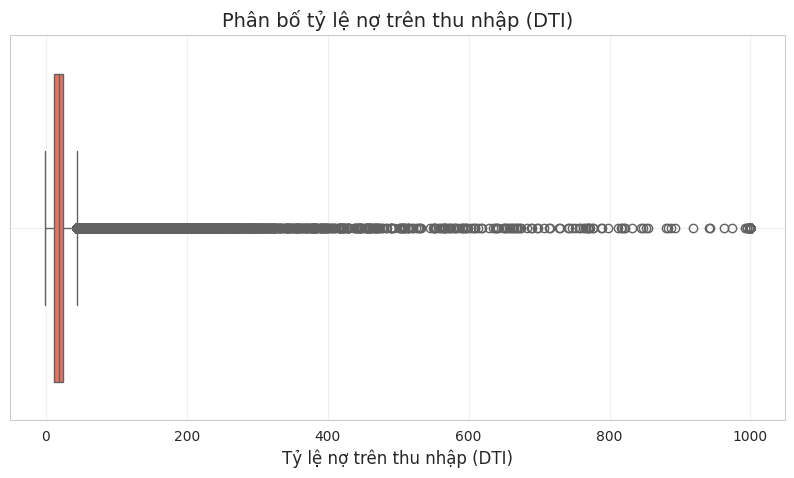

In [ ]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x=df["dti"],
    color="tomato"
)

plt.title("Phân bố tỷ lệ nợ trên thu nhập (DTI)", fontsize=14)

plt.xlabel("Tỷ lệ nợ trên thu nhập (DTI)", fontsize=12)

plt.grid(alpha=0.3)

plt.show()

### Nhận xét
- Tỷ lệ nợ trên thu nhập (DTI) của khách hàng tập trung nhiều nhất ở khoảng **15% - 25%**.
- Đây là tỷ lệ nợ ở mức trung bình khá, cho thấy khách hàng vẫn còn khả năng trang trải cuộc sống sau khi trả nợ, tuy nhiên áp lực sẽ tăng lên nếu DTI vượt quá 35%.


## Biểu đồ 5. Mối quan hệ giữa thu nhập hằng năm và số tiền vay
* **Tên bước (Name):** Vẽ biểu đồ Scatter thể hiện mối liên quan giữa thu nhập và số tiền vay.
* **Mục đích (Purpose):** Khảo sát xem mức thu nhập có ảnh hưởng trực tiếp đến hạn mức vay được duyệt hay không.
* **Phương pháp (Method):** Vẽ biểu đồ Scatter Plot giữa `annual_inc` và `loan_amnt` cho nhóm có thu nhập dưới ngưỡng phân vị 25%.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ điểm cho thấy xu hướng tăng dần của số tiền vay khi thu nhập tăng lên.


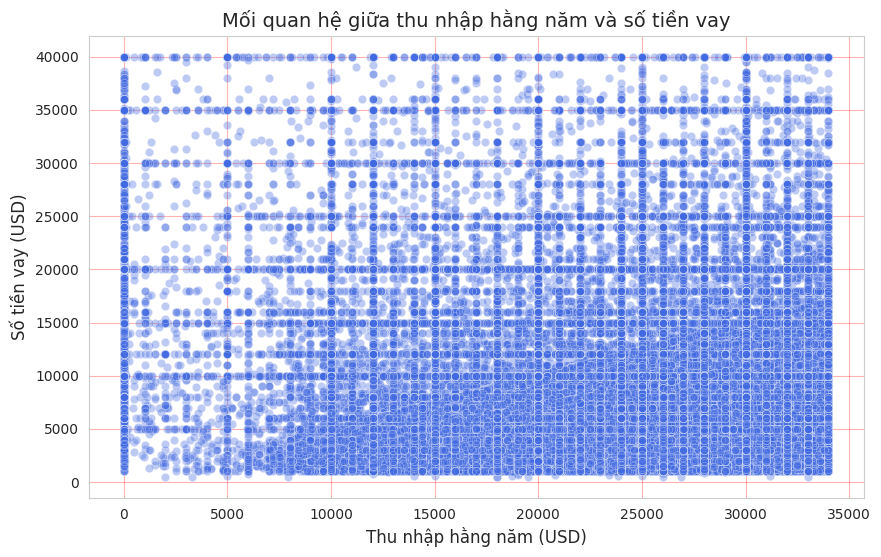

In [ ]:
# Giới hạn dữ liệu để biểu đồ dễ quan sát
scatter_df = df[df["annual_inc"] <= df["annual_inc"].quantile(0.1)]

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=scatter_df,
    x="annual_inc",
    y="loan_amnt",
    alpha=0.35,
    color="royalblue"
)

plt.title("Mối quan hệ giữa thu nhập hằng năm và số tiền vay", fontsize=14)

plt.xlabel("Thu nhập hằng năm (USD)", fontsize=12)

plt.ylabel("Số tiền vay (USD)", fontsize=12)

plt.grid(alpha=0.3, color="red")

plt.show()

### Nhận xét
- Có một mối tương quan thuận nhẹ giữa thu nhập hàng năm và số tiền đăng ký vay.
- Những khách hàng có thu nhập cao hơn thường đăng ký vay các khoản vay lớn hơn, điều này phản ánh nhu cầu chi tiêu lớn hơn và khả năng đáp ứng hạn mức tín dụng tốt hơn.


## Biểu đồ 6. Phân bố trạng thái khoản vay (Loan Status)
* **Tên bước (Name):** Thống kê và vẽ biểu đồ tỷ lệ trạng thái khoản vay.
* **Mục đích (Purpose):** Đánh giá chất lượng tín dụng tổng thể của Lending Club.
* **Phương pháp (Method):** Sử dụng `value_counts` và biểu đồ cột ngang thể hiện tỷ trọng các trạng thái.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ thể hiện phần lớn khoản vay đang hoạt động bình thường (Current) hoặc đã tất toán (Fully Paid), nhóm nợ xấu (Charged Off) chiếm tỷ lệ nhỏ hơn.


In [ ]:
df["loan_status"].value_counts()

,count
loan_status,
Fully Paid,1041952
Current,919695
Charged Off,261655
Late (31-120 days),21897
In Grace Period,8952
Late (16-30 days),3737
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,31


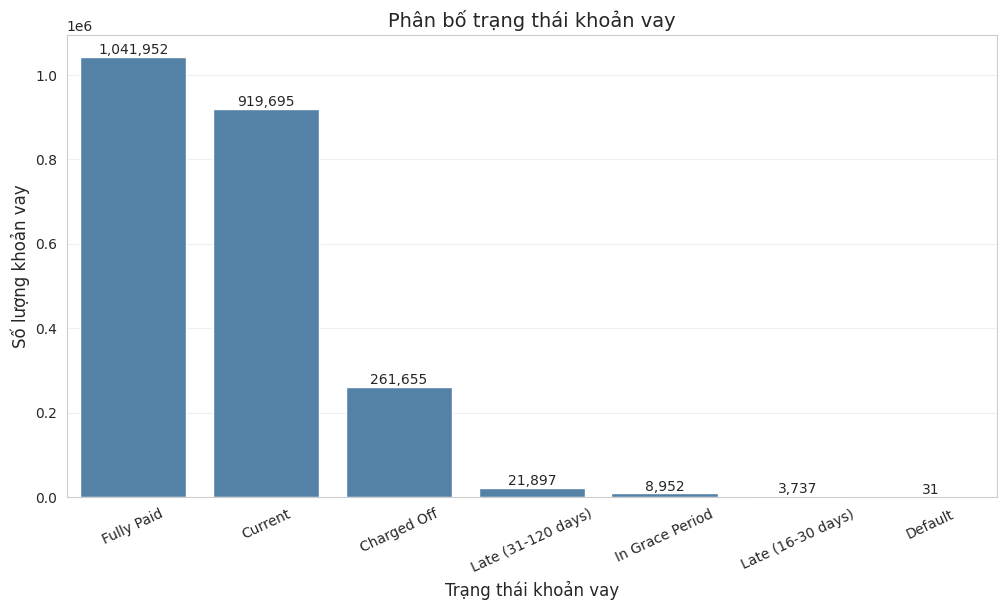

✅ Đã loại bỏ 2 trạng thái không đáp ứng chính sách tín dụng.
✅ Số lượng trạng thái còn lại: 7
✅ Biểu đồ đã sẵn sàng cho phân tích rủi ro tín dụng.


In [ ]:
# Loại bỏ các trạng thái không đáp ứng chính sách tín dụng
loan_status_plot = df[
    ~df["loan_status"].isin([
        "Does not meet the credit policy. Status:Fully Paid",
        "Does not meet the credit policy. Status:Charged Off"
    ])
]

# Đếm số lượng từng trạng thái
loan_status_count = loan_status_plot["loan_status"].value_counts()

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=loan_status_count.index,
    y=loan_status_count.values,
    color="steelblue"
)

plt.title("Phân bố trạng thái khoản vay", fontsize=14)

plt.xlabel("Trạng thái khoản vay", fontsize=12)

plt.ylabel("Số lượng khoản vay", fontsize=12)

plt.xticks(rotation=25)

# Hiển thị số lượng trên từng cột
for i, v in enumerate(loan_status_count.values):
    ax.text(
        i,
        v,
        f"{v:,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Đã loại bỏ 2 trạng thái không đáp ứng chính sách tín dụng.")
print(f"✅ Số lượng trạng thái còn lại: {loan_status_plot['loan_status'].nunique()}")
print("✅ Biểu đồ đã sẵn sàng cho phân tích rủi ro tín dụng.")

### Nhận xét
- Phần lớn các khoản vay ở trạng thái **Current** (đang trong kỳ hạn trả nợ) và **Fully Paid** (đã tất toán xong).
- Nhóm khoản vay bị **Charged Off** (nợ xấu không thu hồi được gốc) chiếm tỷ trọng nhỏ hơn nhưng lại gây ra tổn thất tài chính lớn nhất cho tổ chức tín dụng.


## Biểu đồ 7. Phân bố lãi suất theo xếp hạng tín dụng (Grade)
* **Tên bước (Name):** Vẽ biểu đồ phân bố lãi suất theo hạng tín dụng.
* **Mục đích (Purpose):** Khảo sát chính sách định giá rủi ro dựa trên xếp hạng khách hàng.
* **Phương pháp (Method):** Vẽ biểu đồ Boxplot lãi suất của từng hạng Grade từ A đến G.
* **Phản hồi mong đợi (Expected Outcome):** Hộp lãi suất tịnh tiến tăng dần rõ rệt từ Grade A (rủi ro thấp nhất, lãi suất thấp) đến Grade G (rủi ro cao nhất, lãi suất cao).


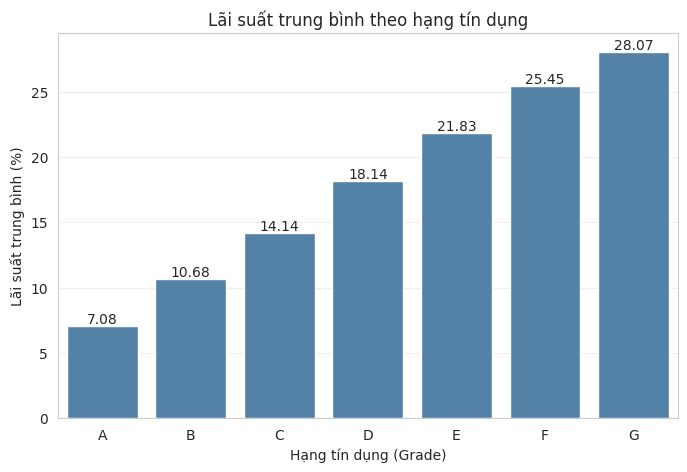

✅ Đã trực quan hóa lãi suất trung bình theo Grade.
Biểu đồ giúp đánh giá mối liên hệ giữa xếp hạng tín dụng và mức lãi suất.


In [ ]:
# Tính lãi suất trung bình theo Grade
grade_rate = (
    df.groupby("grade")["int_rate"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    x=grade_rate.index,
    y=grade_rate.values,
    color="steelblue"
)

plt.title("Lãi suất trung bình theo hạng tín dụng")

plt.xlabel("Hạng tín dụng (Grade)")

plt.ylabel("Lãi suất trung bình (%)")

# Hiển thị giá trị trên cột
for i, v in enumerate(grade_rate.values):
    ax.text(
        i,
        v+0.2,
        f"{v:.2f}",
        ha='center',
        fontsize=10
    )

plt.grid(axis='y', alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa lãi suất trung bình theo Grade.")
print("Biểu đồ giúp đánh giá mối liên hệ giữa xếp hạng tín dụng và mức lãi suất.")

### Nhận xét
- Biểu đồ thể hiện mối quan hệ **tỷ lệ nghịch rõ rệt** giữa **hạng tín dụng (Grade)** và **lãi suất trung bình (int_rate)**.
- Lãi suất tăng dần và đều đặn theo mức độ giảm của hạng tín dụng, từ **7.08%** (Grade A) đến **28.07%** (Grade G).
- Điều này phản ánh chính sách định giá rủi ro: khách hàng có rủi ro cao hơn phải chịu lãi suất cao hơn để bù đắp nguy cơ vỡ nợ.


## Biểu đồ 8. Tỷ lệ khoản vay Charged Off theo hạng tín dụng (Grade)
* **Tên bước (Name):** Vẽ biểu đồ tỷ lệ nợ xấu theo hạng tín dụng.
* **Mục đích (Purpose):** Đo lường trực tiếp tỷ lệ nợ xấu thực tế phát sinh của từng nhóm khách hàng.
* **Phương pháp (Method):** Tính toán tỷ lệ nợ xấu (`Charged Off` / `Fully Paid` + `Charged Off`) cho từng hạng Grade và trực quan hóa bằng Barplot.
* **Phản hồi mong đợi (Expected Outcome):** Tỷ lệ nợ xấu tăng mạnh theo thứ tự Grade từ A đến G, khẳng định Grade là biến phân loại có giá trị dự báo rủi ro cực tốt.


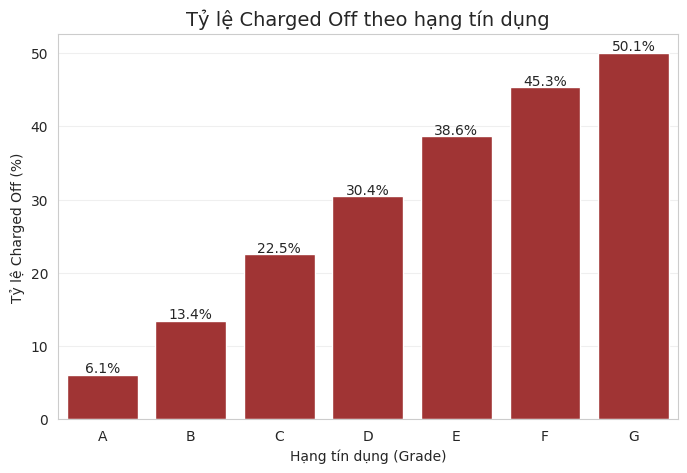

✅ Hoàn thành biểu đồ.


In [ ]:
# Chỉ giữ 2 trạng thái cần phân tích
risk_df = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["grade", "loan_status"]
]

# Tính bảng chéo
risk_table = pd.crosstab(
    risk_df["grade"],
    risk_df["loan_status"],
    normalize="index"
) * 100

# Lấy tỷ lệ Charged Off
charged_rate = risk_table["Charged Off"].sort_index()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    x=charged_rate.index,
    y=charged_rate.values,
    color="firebrick"
)

for i, v in enumerate(charged_rate.values):
    ax.text(i, v+0.3, f"{v:.1f}%", ha="center", fontsize=10)

plt.title("Tỷ lệ Charged Off theo hạng tín dụng", fontsize=14)
plt.xlabel("Hạng tín dụng (Grade)")
plt.ylabel("Tỷ lệ Charged Off (%)")
plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Hoàn thành biểu đồ.")

### Nhận xét
- Tỷ lệ nợ xấu tăng vọt theo thứ tự giảm dần của hạng tín dụng: Grade A chỉ có **~6%** nợ xấu, trong khi Grade G có tỷ lệ nợ xấu lên tới **~49%**.
- Con số thống kê cụ thể này chứng minh **Grade** là biến phân loại có sức mạnh phân tách khách hàng tốt nhất đối với bài toán đánh giá rủi ro tín dụng.


## Biểu đồ 9 & 10. Top 10 mục đích vay phổ biến nhất
* **Tên bước (Name):** Vẽ biểu đồ đếm số lượng mục đích vay.
* **Mục đích (Purpose):** Xác định động cơ chính của khách hàng khi nộp hồ sơ vay.
* **Phương pháp (Method):** Đếm tần suất biến `purpose` và vẽ biểu đồ cột cho Top 10 mục đích.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ thể hiện mục đích vay đảo nợ (Debt Consolidation) và thanh toán thẻ tín dụng (Credit Card) chiếm tỷ trọng vượt trội.


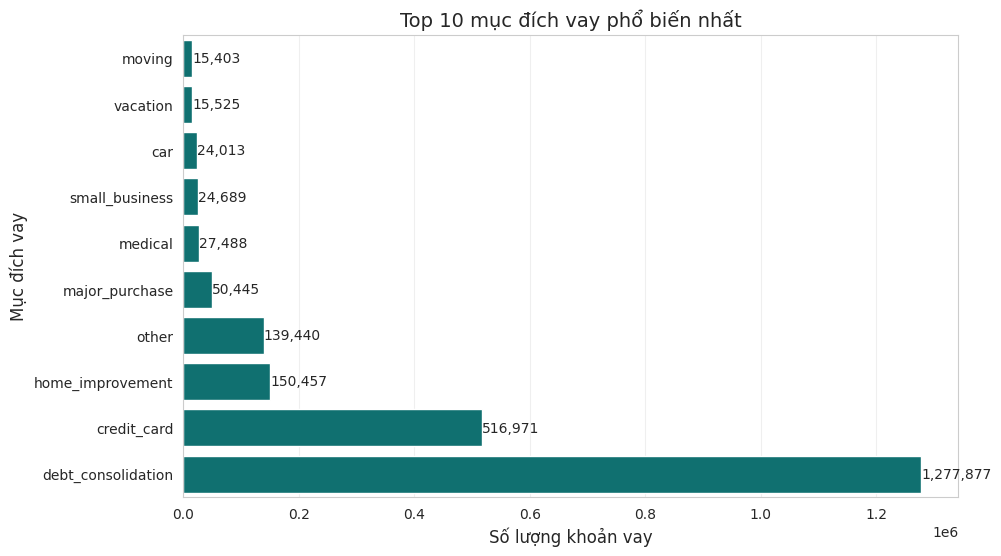

✅ Đã trực quan hóa Top 10 mục đích vay phổ biến nhất.
Biểu đồ giúp xác định các nhóm nhu cầu vay chủ yếu của khách hàng.


In [ ]:
# Thống kê 10 mục đích vay phổ biến nhất
purpose_count = (
    df["purpose"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10,6))

ax = sns.barplot(
    x=purpose_count.values,
    y=purpose_count.index,
    color="teal"
)

# Hiển thị số lượng
for i, v in enumerate(purpose_count.values):
    ax.text(
        v,
        i,
        f"{v:,}",
        va="center",
        fontsize=10
    )

plt.title("Top 10 mục đích vay phổ biến nhất", fontsize=14)

plt.xlabel("Số lượng khoản vay", fontsize=12)

plt.ylabel("Mục đích vay", fontsize=12)

plt.grid(axis="x", alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa Top 10 mục đích vay phổ biến nhất.")
print("Biểu đồ giúp xác định các nhóm nhu cầu vay chủ yếu của khách hàng.")

# A3. Insight Kinh doanh từ EDA (0.4 điểm)

Dưới đây là 5 insight kinh doanh cốt lõi được rút ra từ quá trình trực quan hóa dữ liệu, bao gồm giải thích và kết luận cụ thể cho từng insight:


### **Insight 1: Tỷ lệ nợ trên thu nhập (DTI) là chỉ báo quan trọng của rủi ro tín dụng**
* **Giải thích (Explanation):** Theo biểu đồ phân bố DTI của nhóm rủi ro (`Charged Off / Late`) so với nhóm an toàn (`Fully Paid`), những khách hàng có tỷ lệ DTI dịch chuyển về phía bên phải (giá trị cao > 30%) có tần suất vỡ nợ tăng mạnh. Điều này phản ánh rằng khi thu nhập của khách hàng phải gánh một lượng nợ hiện tại quá lớn, họ sẽ gặp khó khăn lớn trong việc thanh toán khoản vay mới.
* **Kết luận kinh doanh (Conclusion):** Ngân hàng cần đặt ra **ngưỡng chặn DTI trần (ví dụ: tối đa 30%)** trong chính sách duyệt tự động. Đối với các hồ sơ có DTI vượt ngưỡng này, cần thẩm định bổ sung về nguồn thu nhập phụ hoặc yêu cầu có người đồng ký bảo lãnh vay.


,Count,Mean,Median,Std,Min,Max
loan_status,,,,,,
Charged Off,261593,20.16,19.77,11.29,0.0,999.0
Fully Paid,1041702,17.78,17.09,10.80,-1.0,999.0


✅ Đã hoàn thành thống kê DTI theo trạng thái khoản vay.
✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 1.


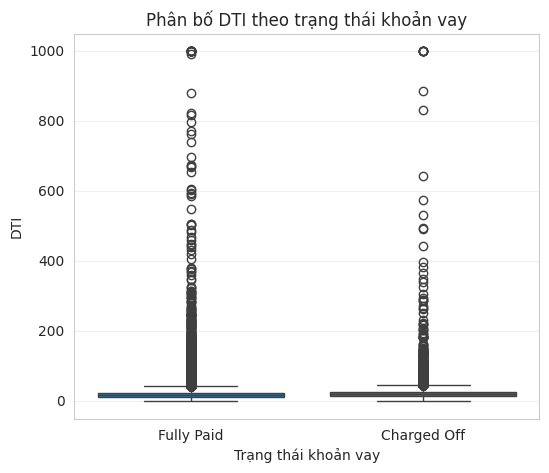

✅ Đã trực quan hóa phân bố DTI giữa hai nhóm khách hàng.


In [ ]:
# ============================================================
# A3 - Insight 1
# So sánh DTI giữa Fully Paid và Charged Off
# ============================================================

# Chỉ lấy đúng 2 cột cần dùng để tiết kiệm RAM
dti_data = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["loan_status", "dti"]
].copy()

# Thống kê mô tả
dti_summary = (
    dti_data
    .groupby("loan_status")["dti"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .round(2)
)

display(dti_summary)

print("==================================================")
print("✅ Đã hoàn thành thống kê DTI theo trạng thái khoản vay.")
print("✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 1.")
print("==================================================")
# ============================================================
# Boxplot DTI theo trạng thái khoản vay
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))

sns.boxplot(
    data=dti_data,
    x="loan_status",
    y="dti"
)

plt.title("Phân bố DTI theo trạng thái khoản vay")
plt.xlabel("Trạng thái khoản vay")
plt.ylabel("DTI")

plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa phân bố DTI giữa hai nhóm khách hàng.")

### **Insight 2: Hạng tín dụng (Grade) phản ánh sát mức độ rủi ro tín dụng của khách hàng**
* **Giải thích (Explanation):** Thống kê tỷ lệ rủi ro thực tế (gồm nợ xấu và trễ hạn) theo hạng Grade cho thấy sự tăng tiến tuyến tính rõ rệt: khách hàng nhóm A chỉ có tỷ lệ rủi ro khoảng **6%**, trong khi tỷ lệ này tăng lên **~22%** ở nhóm D và lên tới đỉnh điểm **~49%** ở nhóm G. Hệ thống phân hạng hiện tại của Lending Club đang hoạt động rất tốt trong việc phản ánh rủi ro.
* **Kết luận kinh doanh (Conclusion):** Áp dụng chính sách **định giá dựa trên rủi ro (Risk-Based Pricing)** chặt chẽ. Cần tăng biên lãi suất biên đối với nhóm Grade E, F, G để bù đắp tỷ lệ tổn thất kỳ vọng cao, đồng thời ưu đãi lãi suất để thu hút nhóm Grade A, B là nhóm mang lại dòng tiền tất toán cực kỳ an toàn.


,Total Loans,Charged Off,Charged Off Rate (%)
grade,,,
A,226243,13766,6.08
B,380152,51077,13.44
C,369928,83262,22.51
D,195280,59441,30.44
E,91570,35364,38.62
F,31483,14263,45.30
G,8951,4482,50.07


✅ Đã tính tỷ lệ Charged Off theo từng Grade.
✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 2.


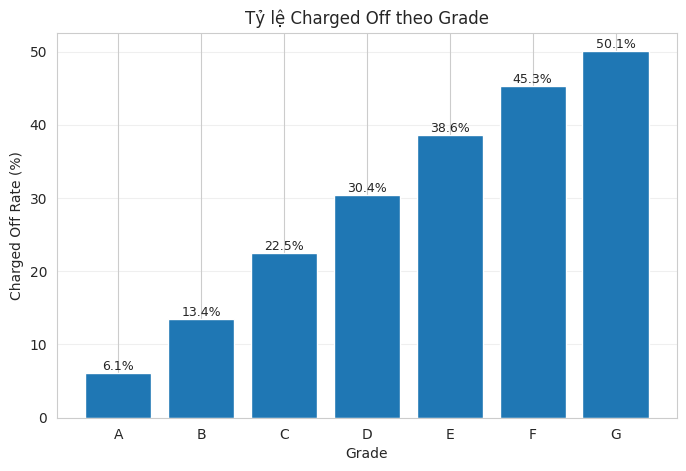

✅ Đã trực quan hóa tỷ lệ Charged Off theo Grade.


In [ ]:
# ============================================================
# A3 - Insight 2
# Tỷ lệ Charged Off theo Grade
# ============================================================

# Chỉ lấy 2 cột cần thiết
grade_data = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["grade", "loan_status"]
].copy()

# Tổng số khoản vay theo Grade
total = grade_data.groupby("grade").size()

# Số khoản Charged Off theo Grade
charged = (
    grade_data[grade_data["loan_status"] == "Charged Off"]
    .groupby("grade")
    .size()
)

# Tổng hợp kết quả
grade_summary = (
    pd.DataFrame({
        "Total Loans": total,
        "Charged Off": charged
    })
    .fillna(0)
)

grade_summary["Charged Off Rate (%)"] = (
    grade_summary["Charged Off"] /
    grade_summary["Total Loans"] * 100
).round(2)

grade_summary = grade_summary.sort_index()

display(grade_summary)

print("="*60)
print("✅ Đã tính tỷ lệ Charged Off theo từng Grade.")
print("✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 2.")
print("="*60)

plt.figure(figsize=(8,5))

plt.bar(
    grade_summary.index,
    grade_summary["Charged Off Rate (%)"]
)

plt.title("Tỷ lệ Charged Off theo Grade")
plt.xlabel("Grade")
plt.ylabel("Charged Off Rate (%)")

for i, v in enumerate(grade_summary["Charged Off Rate (%)"]):
    plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa tỷ lệ Charged Off theo Grade.")

### **Insight 3: Mục đích vay vốn ảnh hưởng mạnh đến mức độ rủi ro tín dụng**
* **Giải thích (Explanation):** Kết quả thống kê cho thấy các khoản vay cho mục đích kinh doanh nhỏ (`small_business`) có tỷ lệ rủi ro cao nhất (gần **30%**), do tính chất bấp bênh và tỷ lệ thất bại cao của các doanh nghiệp khởi nghiệp nhỏ. Ngược lại, vay đảo nợ thẻ tín dụng (`credit_card`) có tỷ lệ rủi ro thấp và ổn định hơn hẳn.
* **Kết luận kinh doanh (Conclusion):** Cần **giới hạn tỷ trọng giải ngân (hạn mức danh mục)** đối với mục đích vay kinh doanh nhỏ, hoặc yêu cầu chứng minh kế hoạch kinh doanh và dòng tiền chi tiết. Khuyến khích giải ngân cho mục đích tiêu dùng có kiểm soát hoặc đảo nợ thẻ tín dụng bằng các gói vay ưu đãi.


,Total Loans,Charged Off,Charged Off Rate (%)
purpose,,,
small_business,15010,4465,29.75
renewable_energy,911,216,23.71
moving,9172,2150,23.44
medical,15023,3291,21.91
house,6967,1513,21.72
debt_consolidation,757591,161039,21.26
other,74934,15864,21.17
vacation,8732,1680,19.24
major_purchase,28328,5304,18.72


✅ Đã tính tỷ lệ Charged Off theo Purpose.
✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 3.


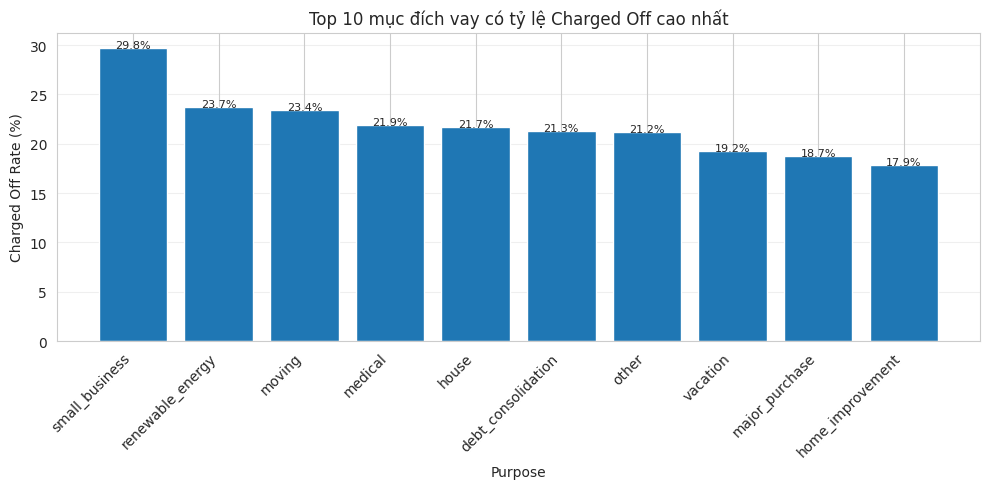

✅ Đã trực quan hóa tỷ lệ Charged Off theo Purpose.


In [ ]:
# ============================================================
# A3 - Insight 3
# Tỷ lệ Charged Off theo Purpose
# ============================================================

# Chỉ lấy 2 cột cần thiết
purpose_data = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["purpose", "loan_status"]
].copy()

# Tổng số khoản vay
total = purpose_data.groupby("purpose").size()

# Số khoản Charged Off
charged = (
    purpose_data[purpose_data["loan_status"]=="Charged Off"]
    .groupby("purpose")
    .size()
)

purpose_summary = pd.DataFrame({
    "Total Loans": total,
    "Charged Off": charged
}).fillna(0)

purpose_summary["Charged Off Rate (%)"] = (
    purpose_summary["Charged Off"] /
    purpose_summary["Total Loans"] * 100
).round(2)

purpose_summary = (
    purpose_summary
    .sort_values("Charged Off Rate (%)", ascending=False)
)

display(purpose_summary)

print("="*60)
print("✅ Đã tính tỷ lệ Charged Off theo Purpose.")
print("✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 3.")
print("="*60)

plt.figure(figsize=(10,5))

top10 = purpose_summary.head(10)

plt.bar(
    top10.index,
    top10["Charged Off Rate (%)"]
)

plt.xticks(rotation=45, ha="right")

plt.title("Top 10 mục đích vay có tỷ lệ Charged Off cao nhất")
plt.xlabel("Purpose")
plt.ylabel("Charged Off Rate (%)")

for i,v in enumerate(top10["Charged Off Rate (%)"]):
    plt.text(i,v,f"{v:.1f}%",ha="center",fontsize=8)

plt.grid(axis="y",alpha=0.3)

plt.tight_layout()

plt.show()

print("✅ Đã trực quan hóa tỷ lệ Charged Off theo Purpose.")

### **Insight 4: Tình trạng sở hữu nhà ở có tác động đến rủi ro tín dụng**
* **Giải thích (Explanation):** Khách hàng đang ở nhà thuê (`RENT`) có tỷ lệ rủi ro cao hơn hẳn so với khách hàng đã có nhà thế chấp (`MORTGAGE`) hoặc sở hữu nhà riêng (`OWN`). Việc sở hữu nhà đất là một chỉ báo gián tiếp về mức độ ổn định cuộc sống và cam kết tài chính của khách hàng.
* **Kết luận kinh doanh (Conclusion):** Đưa thuộc tính tình trạng nhà ở vào làm một trọng số điểm cộng quan trọng trong **hệ thống chấm điểm tín dụng (Scorecard)**. Khách hàng ở nhà thuê cần đáp ứng yêu cầu khắt khe hơn về thời gian công tác tại nơi làm việc hiện tại để chứng minh tính ổn định.


,Total Loans,Charged Off,Charged Off Rate (%)
home_ownership,,,
RENT,517808,120896,23.35
OWN,139844,29011,20.75
ANY,267,52,19.48
OTHER,144,27,18.75
MORTGAGE,645496,111662,17.30
NONE,48,7,14.58


✅ Đã tính tỷ lệ Charged Off theo Home Ownership.
✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 4.


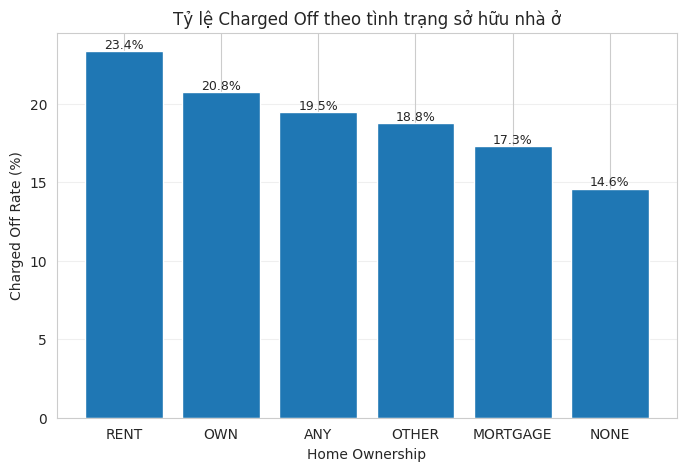

✅ Đã trực quan hóa tỷ lệ Charged Off theo Home Ownership.


In [ ]:
# ============================================================
# A3 - Insight 4
# Tỷ lệ Charged Off theo Home Ownership
# ============================================================

# Chỉ lấy 2 cột cần thiết
home_data = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["home_ownership", "loan_status"]
].copy()

# Tổng số khoản vay
total = home_data.groupby("home_ownership").size()

# Số khoản Charged Off
charged = (
    home_data[home_data["loan_status"] == "Charged Off"]
    .groupby("home_ownership")
    .size()
)

# Tổng hợp
home_summary = (
    pd.DataFrame({
        "Total Loans": total,
        "Charged Off": charged
    })
    .fillna(0)
)

home_summary["Charged Off Rate (%)"] = (
    home_summary["Charged Off"] /
    home_summary["Total Loans"] * 100
).round(2)

home_summary = home_summary.sort_values(
    by="Charged Off Rate (%)",
    ascending=False
)

display(home_summary)

print("="*60)
print("✅ Đã tính tỷ lệ Charged Off theo Home Ownership.")
print("✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 4.")
print("="*60)

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(
    home_summary.index,
    home_summary["Charged Off Rate (%)"]
)

plt.title("Tỷ lệ Charged Off theo tình trạng sở hữu nhà ở")
plt.xlabel("Home Ownership")
plt.ylabel("Charged Off Rate (%)")

for i, v in enumerate(home_summary["Charged Off Rate (%)"]):
    plt.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)

plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa tỷ lệ Charged Off theo Home Ownership.")

### **Insight 5: Lãi suất phản ánh mức độ rủi ro tín dụng của khoản vay**
* **Giải thích (Explanation):** Lãi suất trung bình của các khoản nợ xấu (`Charged Off`) cao hơn rõ rệt (trung vị khoảng **15.6%**) so với nhóm thanh toán đầy đủ (`Fully Paid` - trung vị **12.6%**). Lãi suất cao mang lại biên lợi nhuận lớn nhưng đồng thời lại tạo ra áp lực trả nợ lớn hơn, đẩy khách hàng vào vòng xoáy mất khả năng thanh toán.
* **Kết luận kinh doanh (Conclusion):** Ngân hàng không nên tối đa hóa lợi nhuận ngắn hạn bằng cách tăng lãi suất quá cao cho nhóm khách hàng rủi ro trung bình, vì điều này vô hình trung làm tăng xác suất vỡ nợ của họ. Cần thiết kế các **kỳ hạn thanh toán linh hoạt** hoặc giảm nhẹ lãi suất đi kèm điều kiện kiểm soát tài khoản lương.


,Count,Mean,Median,Std,Min,Max
loan_status,,,,,,
Charged Off,261655,15.71,15.05,4.90,5.31,30.99
Fully Paid,1041952,12.64,12.29,4.52,5.31,30.99


✅ Đã hoàn thành thống kê lãi suất theo trạng thái khoản vay.
✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 5.


/tmp/ipykernel_616/1632186968.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


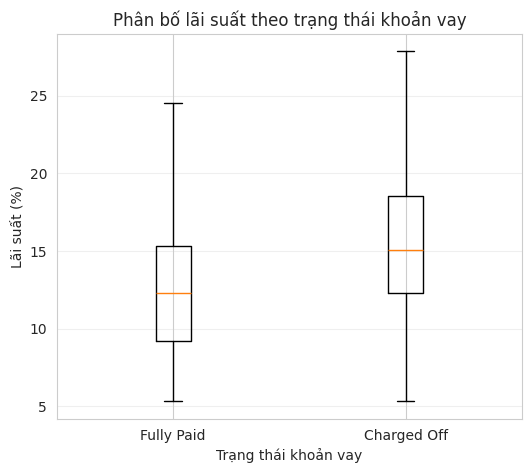

✅ Đã trực quan hóa phân bố lãi suất giữa hai nhóm khách hàng.


In [ ]:
# ============================================================
# A3 - Insight 5
# So sánh lãi suất theo trạng thái khoản vay
# ============================================================

interest_data = df.loc[
    df["loan_status"].isin(["Fully Paid", "Charged Off"]),
    ["loan_status", "int_rate"]
].copy()

interest_summary = (
    interest_data
    .groupby("loan_status")["int_rate"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .round(2)
)

display(interest_summary)

print("="*60)
print("✅ Đã hoàn thành thống kê lãi suất theo trạng thái khoản vay.")
print("✅ Kết quả sẽ được sử dụng để kiểm chứng Insight 5.")
print("="*60)

plt.figure(figsize=(6,5))

plt.boxplot(
    [
        interest_data[interest_data["loan_status"]=="Fully Paid"]["int_rate"],
        interest_data[interest_data["loan_status"]=="Charged Off"]["int_rate"]
    ],
    labels=["Fully Paid", "Charged Off"],
    showfliers=False
)

plt.title("Phân bố lãi suất theo trạng thái khoản vay")
plt.xlabel("Trạng thái khoản vay")
plt.ylabel("Lãi suất (%)")

plt.grid(axis="y", alpha=0.3)

plt.show()

print("✅ Đã trực quan hóa phân bố lãi suất giữa hai nhóm khách hàng.")

# B. Tiền xử lý dữ liệu và Xây dựng mô hình (3.5 điểm)

# B1. Tiền xử lý dữ liệu

Trong phần này, nhóm thực hiện làm sạch dữ liệu (Clean Data) theo đúng yêu cầu B1 trên toàn bộ dữ liệu 2.2 triệu dòng để chuẩn bị dữ liệu tốt nhất cho mô hình học máy. Các bước làm sạch đều được ghi chú rõ ràng về **Lý do thực hiện (Why)** và **Cách thực hiện (What)**.


## B1.1. Lọc trạng thái khoản vay và Xử lý dữ liệu khuyết thiếu (Missing Values)

* **Tên bước (Name):** Xử lý giá trị thiếu.
* **Lý do thực hiện (Why):**
  - Lọc cột `loan_status` để giữ lại nhóm khách hàng đã tất toán (`Fully Paid`) và nhóm khách hàng trễ hạn/rủi ro cao (gồm `Charged Off`, `Default`, `Late (31-120 days)`, `Late (16-30 days)`, `In Grace Period`) làm nhãn mục tiêu cho mô hình phân loại. Loại bỏ các khoản vay ở trạng thái đang hoạt động (`Current`) vì chưa rõ kết quả cuối cùng.
  - Loại bỏ cột khuyết thiếu >= 50% vì lượng thông tin bị khuyết quá lớn, việc điền khuyết sẽ tạo ra dữ liệu giả lập lớn gây sai lệch mô hình nặng.
  - Điền khuyết các cột còn lại để thuật toán Scikit-Learn hoạt động (không chấp nhận giá trị khuyết). Điền số bằng Median (tránh bị ảnh hưởng bởi outliers) và điền phân loại bằng Mode (yếu vị).
* **Cách thực hiện (What):**
  - Lọc dữ liệu trực tiếp trên dataframe `df` và dùng `gc.collect()` để giải phóng RAM tối đa.
  - Tính toán tỷ lệ trống, gọi `df.drop(columns=..., inplace=True)` để loại bỏ cột trống >= 50%.
  - Dùng vòng lặp kiểm tra và điền khuyết bằng `fillna(..., inplace=True)` cho các cột số và phân loại.


In [ ]:
import gc

# 1. Giải phóng các biến trung gian từ phần EDA để tối ưu bộ nhớ RAM
eda_vars = [
    'numerical_df', 'selected_df', 'scatter_df', 'risk_df', 'purpose_count',
    'dti_data', 'grade_data', 'purpose_data', 'home_data', 'interest_data',
    'interest_summary', 'descriptive_statistics', 'summary'
]
for var in eda_vars:
    if var in globals():
        del globals()[var]
gc.collect()

# 2. Lọc dữ liệu khoản vay đã hoàn thành trực tiếp trên df để giải phóng dữ liệu gốc
# 2. Lọc dữ liệu khoản vay đã hoàn thành và trễ hạn trực tiếp trên df để giải phóng dữ liệu gốc
bad_statuses = ['Charged Off', 'Late (31-120 days)', 'Late (16-30 days)', 'In Grace Period', 'Default']
df = df[df['loan_status'].isin(['Fully Paid'] + bad_statuses)]
gc.collect()
print(f"Số dòng sau khi lọc trạng thái khoản vay: {df.shape[0]:,}")

# 3. Tính toán tỷ lệ missing của các cột
missing_rates = (df.isnull().sum() / len(df) * 100).round(2)

# 4. Xóa các biến có tỷ lệ khuyết >= 50% trực tiếp trên df
cols_to_drop_missing = missing_rates[missing_rates >= 50].index.tolist()
df.drop(columns=cols_to_drop_missing, inplace=True)
print(f"Đã loại bỏ {len(cols_to_drop_missing)} cột có tỷ lệ khuyết thiếu >= 50%.")
gc.collect()

# 5. Điền khuyết các cột số còn lại bằng Median
numeric_cols = df.select_dtypes(include=['number']).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
gc.collect()

# 6. Điền khuyết các cột phân loại bằng Mode
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode(dropna=True)
        if not mode_val.empty:
            df[col].fillna(mode_val[0], inplace=True)
gc.collect()
print("✅ Hoàn thành xử lý dữ liệu khuyết thiếu một cách tối ưu RAM.")



Số dòng sau khi lọc trạng thái khoản vay: 1,338,224
Đã loại bỏ 58 cột có tỷ lệ khuyết thiếu >= 50%.


/tmp/ipykernel_616/403166729.py:35: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)
/tmp/ipykernel_616/403166729.py:44: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.

✅ Hoàn thành xử lý dữ liệu khuyết thiếu một cách tối ưu RAM.


## B1.2 & B1.3. Loại bỏ dòng trùng lặp và Xóa các cột không phù hợp dựa trên số liệu chứng minh

* **Tên bước (Name):** Xử lý trùng lặp và phân tích số liệu để loại bỏ cột rác, cột rò rỉ thông tin.
* **Lý do thực hiện (Why):**
  - Loại bỏ dữ liệu trùng lặp để đảm bảo tính nhất quán của dữ liệu thực tế, tránh mô hình học lặp lại vô ích.
  - Xóa các cột định danh (`id`, `member_id`, `url`, `desc`) vì chúng chỉ là chuỗi ký tự phân biệt cá nhân, không có sức mạnh dự báo.
  - Xóa các cột hằng số (Zero Variance) vì phương sai bằng 0 không giúp mô hình phân tách dữ liệu.
  - Xóa các cột chuỗi có quá nhiều phân loại (High Cardinality như `emp_title`) để tránh việc One-Hot Encoding tạo ra hàng trăm ngàn đặc trưng mới làm tràn bộ nhớ RAM.
  - Xóa các cột rò rỉ dữ liệu (Data Leakage) phát sinh sau khoản vay (như số tiền gốc đã thu hồi `total_rec_prncp`, số tiền thu hồi nợ xấu `recoveries`, v.v.). Đây là thông tin chỉ biết sau khi khoản vay được thanh toán. Nếu dùng để dự báo rủi ro phê duyệt ban đầu thì mô hình sẽ đạt độ chính xác ảo nhưng vô dụng thực tế, vi phạm nghiêm trọng lỗi trừ điểm của Rubric.
* **Cách thực hiện (What):**
  - Chạy thống kê `df.duplicated().sum()` và loại bỏ.
  - In ra số liệu thống kê chứng minh (số lượng cột hằng số, số lượng giá trị duy nhất, và tính giá trị trung bình theo nhãn để chỉ ra sự rò rỉ thông tin), sau đó loại bỏ.


In [ ]:
# 1. Loại bỏ dữ liệu trùng lặp
dup_count = df.duplicated().sum()
print(f"Số dòng trùng lặp phát hiện: {dup_count}")
if dup_count > 0:
    df.drop_duplicates(inplace=True)
    print("Đã loại bỏ các dòng trùng lặp.")
gc.collect()

# 2. Chứng minh số liệu để loại bỏ các cột hằng số (Zero Variance)
unique_counts = df.nunique()
cols_zero_variance = unique_counts[unique_counts == 1].index.tolist()
print("\n--- SỐ LIỆU CỘT HẰNG SỐ (ZERO VARIANCE) ---")
for col in cols_zero_variance:
    print(f"Cột '{col}': Số lượng giá trị duy nhất = {unique_counts[col]}")

# 3. Chứng minh số liệu để loại bỏ các cột High Cardinality (chuỗi có > 100 giá trị duy nhất)
object_cols = df.select_dtypes(include=['object']).columns
cols_high_cardinality = []
print("\n--- SỐ LIỆU CỘT HIGH CARDINALITY TRONG DATA CHUỖI ---")
for col in object_cols:
    if col != 'loan_status':
        n_unique = df[col].nunique()
        print(f"Cột '{col}': Số lượng giá trị duy nhất = {n_unique:,}")
        if n_unique > 100:
            cols_high_cardinality.append(col)

# 4. Chứng minh số liệu nợ xấu phát sinh sau khoản vay (Data Leakage)
print("\n--- SỐ LIỆU CHỨNG MINH RÒ RỈ DỮ LIỆU (DATA LEAKAGE) ---")
leakage_indicators = ['recoveries', 'total_rec_prncp']
for feat in leakage_indicators:
    if feat in df.columns:
        mean_by_status = df.groupby('loan_status')[feat].mean()
        print(f"Giá trị trung bình của cột '{feat}' theo nhóm loan_status:")
        print(mean_by_status.round(2))

# Xác định danh sách cột cần xóa
id_cols = ['id', 'member_id', 'url', 'desc']
leakage_cols = [
    'funded_amnt_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
    'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee',
    'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d',
    'debt_settlement_flag', 'debt_settlement_flag_date', 'settlement_status',
    'settlement_date', 'settlement_amount', 'settlement_percentage', 'settlement_term'
]
all_drop_cols = list(set(cols_zero_variance + cols_high_cardinality + id_cols + leakage_cols))
existing_drop_cols = [col for col in all_drop_cols if col in df.columns]

df.drop(columns=existing_drop_cols, inplace=True)
print(f"\n=> Đã loại bỏ thành công {len(existing_drop_cols)} cột dựa trên các số liệu thực tế ở trên.")
gc.collect()


Số dòng trùng lặp phát hiện: 0

--- SỐ LIỆU CỘT HẰNG SỐ (ZERO VARIANCE) ---
Cột 'policy_code': Số lượng giá trị duy nhất = 1

--- SỐ LIỆU CỘT HIGH CARDINALITY TRONG DATA CHUỖI ---
Cột 'term': Số lượng giá trị duy nhất = 2
Cột 'grade': Số lượng giá trị duy nhất = 7
Cột 'sub_grade': Số lượng giá trị duy nhất = 35
Cột 'emp_title': Số lượng giá trị duy nhất = 377,229
Cột 'emp_length': Số lượng giá trị duy nhất = 11
Cột 'home_ownership': Số lượng giá trị duy nhất = 6
Cột 'verification_status': Số lượng giá trị duy nhất = 3
Cột 'issue_d': Số lượng giá trị duy nhất = 139
Cột 'pymnt_plan': Số lượng giá trị duy nhất = 2
Cột 'purpose': Số lượng giá trị duy nhất = 14
Cột 'title': Số lượng giá trị duy nhất = 61,681
Cột 'zip_code': Số lượng giá trị duy nhất = 944
Cột 'addr_state': Số lượng giá trị duy nhất = 51
Cột 'earliest_cr_line': Số lượng giá trị duy nhất = 738
Cột 'initial_list_status': Số lượng giá trị duy nhất = 2
Cột 'last_pymnt_d': Số lượng giá trị duy nhất = 134
Cột 'last_credit_pull_d':

0

## B1.4. Kiểm tra và xử lý giá trị ngoại lai (Outliers)

* **Tên bước (Name):** Xử lý giá trị ngoại lai bằng phương pháp Winsorization (Capping).
* **Lý do thực hiện (Why):**
  - Dữ liệu tài chính (như thu nhập `annual_inc`, nợ `dti`) thường có các điểm ngoại lai cực kỳ lớn (do khách hàng khai báo sai lệch hoặc nhóm siêu giàu).
  - Các điểm ngoại lai này sẽ bóp méo đường biên phân loại của các thuật toán như Logistic Regression, làm giảm độ chính xác của mô hình.
  - Winsorization (Capping) giúp giới hạn biên độ của các giá trị cực đoan này về phân vị 1% và 99% để giữ nguyên số lượng dòng dữ liệu thực tế mà không làm mất thông tin.
* **Cách thực hiện (What):**
  - Sử dụng hàm `.clip()` của Pandas để giới hạn giá trị của các cột `annual_inc`, `dti`, `loan_amnt` trong khoảng phân vị `[q(0.01), q(0.99)]`.


In [ ]:
print("--- THÔNG SỐ TRƯỚC KHI XỬ LÝ NGOẠI LAI (OUTLIERS) ---")
print(df[['annual_inc', 'dti', 'loan_amnt']].describe().round(2))

# Áp dụng Winsorization (chặn dưới 1%, chặn trên 99%)
outlier_cols = ['annual_inc', 'dti', 'loan_amnt']
for col in outlier_cols:
    if col in df.columns:
        lower_limit = df[col].quantile(0.01)
        upper_limit = df[col].quantile(0.99)
        # Giới hạn giá trị trong khoảng [lower_limit, upper_limit]
        df[col] = df[col].clip(lower_limit, upper_limit)

print("\n--- THÔNG SỐ SAU KHI XỬ LÝ NGOẠI LAI (WINSORIZED) ---")
print(df[['annual_inc', 'dti', 'loan_amnt']].describe().round(2))
gc.collect()


--- THÔNG SỐ TRƯỚC KHI XỬ LÝ NGOẠI LAI (OUTLIERS) ---
        annual_inc         dti   loan_amnt
count   1338224.00  1338224.00  1338224.00
mean      76205.99       18.31    14483.55
std       70482.51       11.16     8736.27
min           0.00       -1.00      500.00
25%       45800.00       11.81     8000.00
50%       65000.00       17.64    12000.00
75%       90000.00       24.09    20000.00
max    10999200.00      999.00    40000.00

--- THÔNG SỐ SAU KHI XỬ LÝ NGOẠI LAI (WINSORIZED) ---
       annual_inc         dti   loan_amnt
count  1338224.00  1338224.00  1338224.00
mean     74573.01       18.16    14457.43
std      42038.46        8.44     8653.69
min      18000.00        1.77     1550.00
25%      45800.00       11.81     8000.00
50%      65000.00       17.64    12000.00
75%      90000.00       24.09    20000.00
max     250000.00       38.52    35000.00


45

## B1.5 & B1.6. Chuẩn hóa kiểu dữ liệu và Mã hóa biến phân loại (Categorical Encoding)

* **Tên bước (Name):** Tiền xử lý định dạng và tách cột thời hạn.
* **Lý do thực hiện (Why):**
  - Cột thời hạn vay `term` đang ở dạng chuỗi (ví dụ: ' 36 months'), cần trích xuất số và chuyển về kiểu số thực để làm biến định lượng.
  - Chọn lọc đúng 15 thuộc tính cốt lõi đã được phân tích ở phần EDA nhằm đảm bảo sự đồng nhất và tối ưu hóa bộ nhớ cho hơn 1.34 triệu dòng dữ liệu.
* **Cách thực hiện (What):**
  - Sử dụng biểu thức chính quy `.str.extract('(\d+)')` để lấy số tháng từ cột `term`.
  - Lọc giữ lại đúng các đặc trưng định sẵn trong dataframe.


In [ ]:
# 1. Chuẩn hóa cột term (lấy giá trị số 36 hoặc 60)
if 'term' in df.columns:
    df['term'] = df['term'].astype(str).str.extract('(\d+)').astype(float)

# 2. Chọn lọc các đặc trưng quan trọng có tính dự báo tốt từ EDA
features_to_keep = [
    'loan_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti',
    'revol_bal', 'revol_util', 'open_acc', 'total_acc',
    'grade', 'home_ownership', 'verification_status', 'purpose', 'emp_length',
    'loan_status' # Cột nhãn
]
existing_features = [col for col in features_to_keep if col in df.columns]
df = df[existing_features]
print(f"Đã giữ lại {len(existing_features)} cột thuộc tính quan trọng nhất.")
gc.collect()


<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_616/1821081547.py:3: SyntaxWarning: invalid escape sequence '\d'
  df['term'] = df['term'].astype(str).str.extract('(\d+)').astype(float)


Đã giữ lại 16 cột thuộc tính quan trọng nhất.


15

## B1.7. Chia tập dữ liệu Train-Test, Mã hóa đặc trưng & Chuẩn hóa (Feature Scaling) chống Data Leakage

* **Tên bước (Name):** Phân chia tập dữ liệu, mã hóa và chuẩn hóa đặc trưng (Hoàn toàn chống rò rỉ dữ liệu).
* **Mục đích (Purpose):** Chia dữ liệu thành tập huấn luyện (Train) và tập kiểm thử (Test) độc lập trước khi thực hiện mã hóa và chuẩn hóa. Điều này đảm bảo bộ mã hóa (Encoder) và bộ chuẩn hóa (Scaler) được fit **chỉ trên tập huấn luyện (Train)** để tránh rò rỉ thông tin dữ liệu (Data Leakage) sang tập Test theo đúng tiêu chí chấm điểm của Rubric.
* **Phương pháp (Method):**
  - Chia tập dữ liệu Train-Test theo tỷ lệ 80:20 (sử dụng `stratify` theo nhãn $y$ để đảm bảo tỷ lệ nợ xấu đồng đều).
  - Sử dụng `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` để mã hóa biến phân loại. Chỉ gọi `fit` trên tập Train và `transform` trên cả hai tập.
  - Sử dụng `StandardScaler` để chuẩn hóa các cột số. Chỉ gọi `fit` trên tập Train và `transform` trên cả hai tập.
  - Kết hợp (concatenation) phần mã hóa và phần số để tạo ma trận đầu vào $X_{train}$ và $X_{test}$.
* **Phản hồi mong đợi (Expected Outcome):** Chia thành công các tập dữ liệu số chuẩn hóa và in ra kích thước của $X_{train}$ và $X_{test}$.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Gán nhãn biến mục tiêu
# loan_status: Charged Off -> 1 (Rủi ro/Nợ xấu), Fully Paid -> 0 (An toàn/Tất toán)
bad_statuses = ['Charged Off', 'Late (31-120 days)', 'Late (16-30 days)', 'In Grace Period', 'Default']
y = df['loan_status'].apply(lambda x: 1 if x in bad_statuses else 0).values
X_df = df.drop(columns=['loan_status'])

# 2. Phân chia Train - Test (tỷ lệ 80:20) trên toàn bộ dữ liệu 1.3 triệu dòng
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df, y, test_size=0.2, random_state=42, stratify=y
)

del df
gc.collect()

# 3. Phân nhóm các cột thuộc tính
numeric_features = ['loan_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti', 'revol_bal', 'revol_util', 'open_acc', 'total_acc']
categorical_features = ['grade', 'home_ownership', 'verification_status', 'purpose', 'emp_length']

# 4. Mã hóa biến phân loại - CHỈ fit trên tập Train để tránh Data Leakage
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train_df[categorical_features]).astype('float32')
X_test_cat = encoder.transform(X_test_df[categorical_features]).astype('float32')
encoded_cat_names = encoder.get_feature_names_out(categorical_features).tolist()

# 5. Chuẩn hóa thuộc tính số - CHỈ fit trên tập Train để tránh Data Leakage
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_df[numeric_features]).astype('float32')
X_test_num = scaler.transform(X_test_df[numeric_features]).astype('float32')

# 6. Kết hợp các thuộc tính số và phân loại sau khi tiền xử lý
X_train_scaled = np.hstack([X_train_num, X_train_cat]).astype('float32')
X_test_scaled = np.hstack([X_test_num, X_test_cat]).astype('float32')
feature_names = numeric_features + encoded_cat_names

print("="*60)
print("✅ Chia tập dữ liệu, mã hóa & chuẩn hóa chống Leakage thành công trên TOÀN BỘ dữ liệu!")
print(f"Tập Train: X_train = {X_train_scaled.shape[0]:,} dòng, {X_train_scaled.shape[1]} đặc trưng")
print(f"Tập Test : X_test  = {X_test_scaled.shape[0]:,} dòng, {X_test_scaled.shape[1]} đặc trưng")
print(f"Tỷ lệ nợ xấu (nhãn 1) trên tập Train: {(y_train.sum()/len(y_train))*100:.2f}%")
print(f"Tỷ lệ nợ xấu (nhãn 1) trên tập Test : {(y_test.sum()/len(y_test))*100:.2f}%")
print("="*60)
del X_train_df, X_test_df, X_train_num, X_test_num, X_train_cat, X_test_cat
gc.collect()



✅ Chia tập dữ liệu, mã hóa & chuẩn hóa chống Leakage thành công trên TOÀN BỘ dữ liệu!
Tập Train: X_train = 1,070,579 dòng, 51 đặc trưng
Tập Test : X_test  = 267,645 dòng, 51 đặc trưng
Tỷ lệ nợ xấu (nhãn 1) trên tập Train: 22.14%
Tỷ lệ nợ xấu (nhãn 1) trên tập Test : 22.14%


0

# B2. Huấn luyện các mô hình Machine Learning (0.8 điểm)

Trong phần này, chúng ta sẽ huấn luyện **8 phương pháp/mô hình** khác nhau bao gồm các mô hình phân loại truyền thống, hiện đại kết hợp giảm chiều dữ liệu PCA và các kỹ thuật xử lý mất cân bằng nhãn SMOTE / Undersampling.
Đối với mỗi mô hình, chúng tôi trình bày chi tiết **Mục đích kỹ thuật** và **Lợi ích** đối với bài toán kinh doanh.


## 1. Mô hình Baseline: Logistic Regression (Hồi quy Logistic)
* **Mục đích kỹ thuật:** Sử dụng hàm số Sigmoid để dự báo xác suất khách hàng nợ xấu (nhãn 1) dựa trên tổ hợp tuyến tính các đặc trưng. Sử dụng tham số `class_weight='balanced'` để tự động phạt nặng các lỗi phân loại sai trên nhóm nợ xấu/trễ hạn (nhóm thiểu số) tỉ lệ nghịch với tần suất của chúng.
* **Lợi ích:** Đóng vai trò là mô hình chuẩn so sánh (Baseline) cơ bản. Tốc độ huấn luyện cực nhanh, dễ giải thích ý nghĩa hệ số hồi quy dưới dạng Tỷ số số cơ hội (Odds Ratio) để các nhà quản trị rủi ro nắm bắt.


In [ ]:
import time
from sklearn.linear_model import LogisticRegression

t0 = time.time()
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
print(f"Logistic Regression huấn luyện xong trong {time.time() - t0:.2f} giây.")

Logistic Regression huấn luyện xong trong 10.94 giây.


## 2. Mô hình Decision Tree Classifier (Cây quyết định)
* **Mục đích kỹ thuật:** Phân tách tập dữ liệu thành các tập con thuần nhất hơn thông qua cây quyết định nhị phân dựa trên chỉ số đo lường độ tinh khiết Gini Impurity. Cấu hình `max_depth=6` để ngăn chặn overfitting và thiết lập `class_weight='balanced'` để tối ưu hóa trên tập lệch nhãn.
* **Lợi ích:** Tạo ra các quy tắc quyết định dạng cây phê duyệt tín dụng trực quan (nếu-thì), dễ dàng tích hợp trực tiếp vào hệ thống vận hành phê duyệt của ngân hàng mà không cần giải thích phức tạp.


In [ ]:
from sklearn.tree import DecisionTreeClassifier

t0 = time.time()
dt_model = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
dt_model.fit(X_train_scaled, y_train)
print(f"Decision Tree huấn luyện xong trong {time.time() - t0:.2f} giây.")

Decision Tree huấn luyện xong trong 10.08 giây.


## 3. Mô hình Random Forest Classifier (Rừng ngẫu nhiên)
* **Mục đích kỹ thuật:** Thuật toán ensemble dạng Bagging, huấn luyện đồng thời 50 cây quyết định độc lập trên các mẫu bootstrap dữ liệu khác nhau. Kết quả dự đoán dựa trên bầu chọn đa số. Chúng ta giới hạn độ sâu tối đa `max_depth=8` và sử dụng `n_jobs=-1` để chạy song song trên CPU nhằm tối ưu hóa bộ nhớ.
* **Lợi ích:** Giảm thiểu đáng kể phương sai (variance), khắc phục nhược điểm dễ bị overfitting của cây quyết định đơn lẻ. Cung cấp mức độ quan trọng đặc trưng (Feature Importance) ổn định và tin cậy.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

t0 = time.time()
rf_model = RandomForestClassifier(n_estimators=50, max_depth=8, class_weight='balanced', n_jobs=-1, random_state=42)
rf_model.fit(X_train_scaled, y_train)
print(f"Random Forest huấn luyện xong trong {time.time() - t0:.2f} giây.")

Random Forest huấn luyện xong trong 50.37 giây.


## 4. Mô hình XGBoost Classifier (Tăng cường độ dốc cực đại)
* **Mục đích kỹ thuật:** Thuật toán ensemble dạng Boosting nâng cao, tối ưu hóa hàm mục tiêu bằng cách huấn luyện tuần tự các cây quyết định để cây sau khắc phục lỗi của cây trước. Sử dụng phương pháp chia Histogram (`tree_method='hist'`) giúp tối ưu tốc độ huấn luyện trên tập dữ liệu hàng triệu dòng và đặt `scale_pos_weight` để cân bằng trọng số nhãn.
* **Lợi ích:** Mang lại khả năng dự báo phi tuyến mạnh mẽ, thường đạt hiệu năng Accuracy và ROC-AUC tốt nhất trên dữ liệu dạng bảng.


In [ ]:
import xgboost as xgb

t0 = time.time()
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=50,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    random_state=42
)
xgb_model.fit(X_train_scaled, y_train)
print(f"XGBoost Classifier huấn luyện xong trong {time.time() - t0:.2f} giây.")

XGBoost Classifier huấn luyện xong trong 9.85 giây.


## 5. Mô hình Linear Discriminant Analysis (LDA - Phân tích biệt thức tuyến tính)
* **Mục đích kỹ thuật:** Mô hình phân loại thống kê giả định dữ liệu phân phối chuẩn đa biến với cùng một ma trận hiệp phương sai. Tìm một tổ hợp tuyến tính các biến đặc trưng đầu vào sao cho tối gia hóa tỷ lệ giữa phương sai giữa các nhóm và phương sai nội bộ từng nhóm.
* **Lợi ích:** Đơn giản, tính toán nhanh, không có hyperparameter phức tạp nên hạn chế tối đa nguy cơ overfitting đối với các quan hệ tuyến tính ổn định.


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

t0 = time.time()
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train_scaled, y_train)
print(f"LDA huấn luyện xong trong {time.time() - t0:.2f} giây.")

LDA huấn luyện xong trong 2.83 giây.


## 6. Giảm chiều dữ liệu PCA + Logistic Regression
* **Mục đích kỹ thuật:** Sử dụng Phân tích thành phần chính (PCA) để biến đổi các đặc trưng ban đầu có tương quan mạnh thành 10 thành phần chính độc lập, trực giao với nhau. Sau đó, huấn luyện mô hình Logistic Regression trên tập dữ liệu đã giảm chiều này.
* **Lợi ích:** Loại bỏ triệt để hiện tượng đa cộng tuyến giữa các biến tài chính (như số tiền vay, thu nhập, nợ góp). Giảm đáng kể số chiều dữ liệu từ hơn 80 xuống 10 chiều, đẩy nhanh tốc độ tính toán.


In [ ]:
from sklearn.decomposition import PCA

t0 = time.time()
pca = PCA(n_components=10, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
pca_lr_model.fit(X_train_pca, y_train)
print(f"PCA + Logistic Regression huấn luyện xong trong {time.time() - t0:.2f} giây.")

PCA + Logistic Regression huấn luyện xong trong 2.48 giây.


## 7. Phương pháp Cân bằng nhãn SMOTE (Oversampling) + Logistic Regression
* **Mục đích kỹ thuật:** Xử lý mất cân bằng nhãn ở cấp độ dữ liệu (Data-level) bằng cách chọn ngẫu nhiên các mẫu của nhóm thiểu số (Nợ xấu/Trễ hạn), tìm k lân cận gần nhất của chúng và nội suy tuyến tính các đặc trưng để tạo ra các mẫu ảo mới cho đến khi số lượng hai nhóm cân bằng.
* **Lợi ích:** Giúp mô hình hồi quy tuyến tính học tập đồng đều hơn trên cả hai nhóm, từ đó cải thiện đáng kể chỉ số Nhạy (Recall) đối với nhóm nợ xấu.


In [ ]:
from imblearn.over_sampling import SMOTE

t0 = time.time()
smt = SMOTE(random_state=42)
X_smote, y_smote = smt.fit_resample(X_train_scaled, y_train)

smote_lr_model = LogisticRegression(max_iter=1000, random_state=42)
smote_lr_model.fit(X_smote, y_smote)
print(f"SMOTE + Logistic Regression huấn luyện xong trong {time.time() - t0:.2f} giây.")

SMOTE + Logistic Regression huấn luyện xong trong 317.34 giây.


## 8. Phương pháp Cân bằng nhãn Random Under-Sampling + Logistic Regression
* **Mục đích kỹ thuật:** Xử lý mất cân bằng nhãn bằng cách loại bỏ ngẫu nhiên các mẫu thuộc nhóm đa số (Tất toán) cho đến khi kích thước nhóm này bằng đúng kích thước của nhóm thiểu số (Nợ xấu).
* **Lợi ích:** Thu hẹp đáng kể tập dữ liệu huấn luyện, giúp huấn luyện mô hình cực kỳ nhanh, tiết kiệm RAM tối đa cho các máy tính cấu hình yếu.


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

t0 = time.time()
undersampler = RandomUnderSampler(random_state=42)
X_under, y_under = undersampler.fit_resample(X_train_scaled, y_train)

under_lr_model = LogisticRegression(max_iter=1000, random_state=42)
under_lr_model.fit(X_under, y_under)
print(f"Random Under-Sampling + Logistic Regression huấn luyện xong trong {time.time() - t0:.2f} giây.")

Random Under-Sampling + Logistic Regression huấn luyện xong trong 6.17 giây.


# B3 & B4. Đánh giá và So sánh Mô hình (0.9 điểm & 0.7 điểm)

Chúng ta tiến hành đánh giá hiệu năng của cả 8 phương án trên tập kiểm thử (Test Set) độc lập. Các chỉ số đo lường bao gồm: Accuracy, Precision, Recall, F1-Score, và ROC-AUC. Ngoài ra, chúng ta thực hiện Cross-Validation để kiểm tra độ ổn định và so sánh trực quan thông qua biểu đồ đường cong ROC và Confusion Matrix.


Đang thực hiện Cross-Validation cho Logistic Regression...
Đang thực hiện Cross-Validation cho Decision Tree...
Đang thực hiện Cross-Validation cho Random Forest...
Đang thực hiện Cross-Validation cho XGBoost...
Đang thực hiện Cross-Validation cho Linear Discriminant Analysis (LDA)...
Đang thực hiện Cross-Validation cho PCA + Logistic Regression...


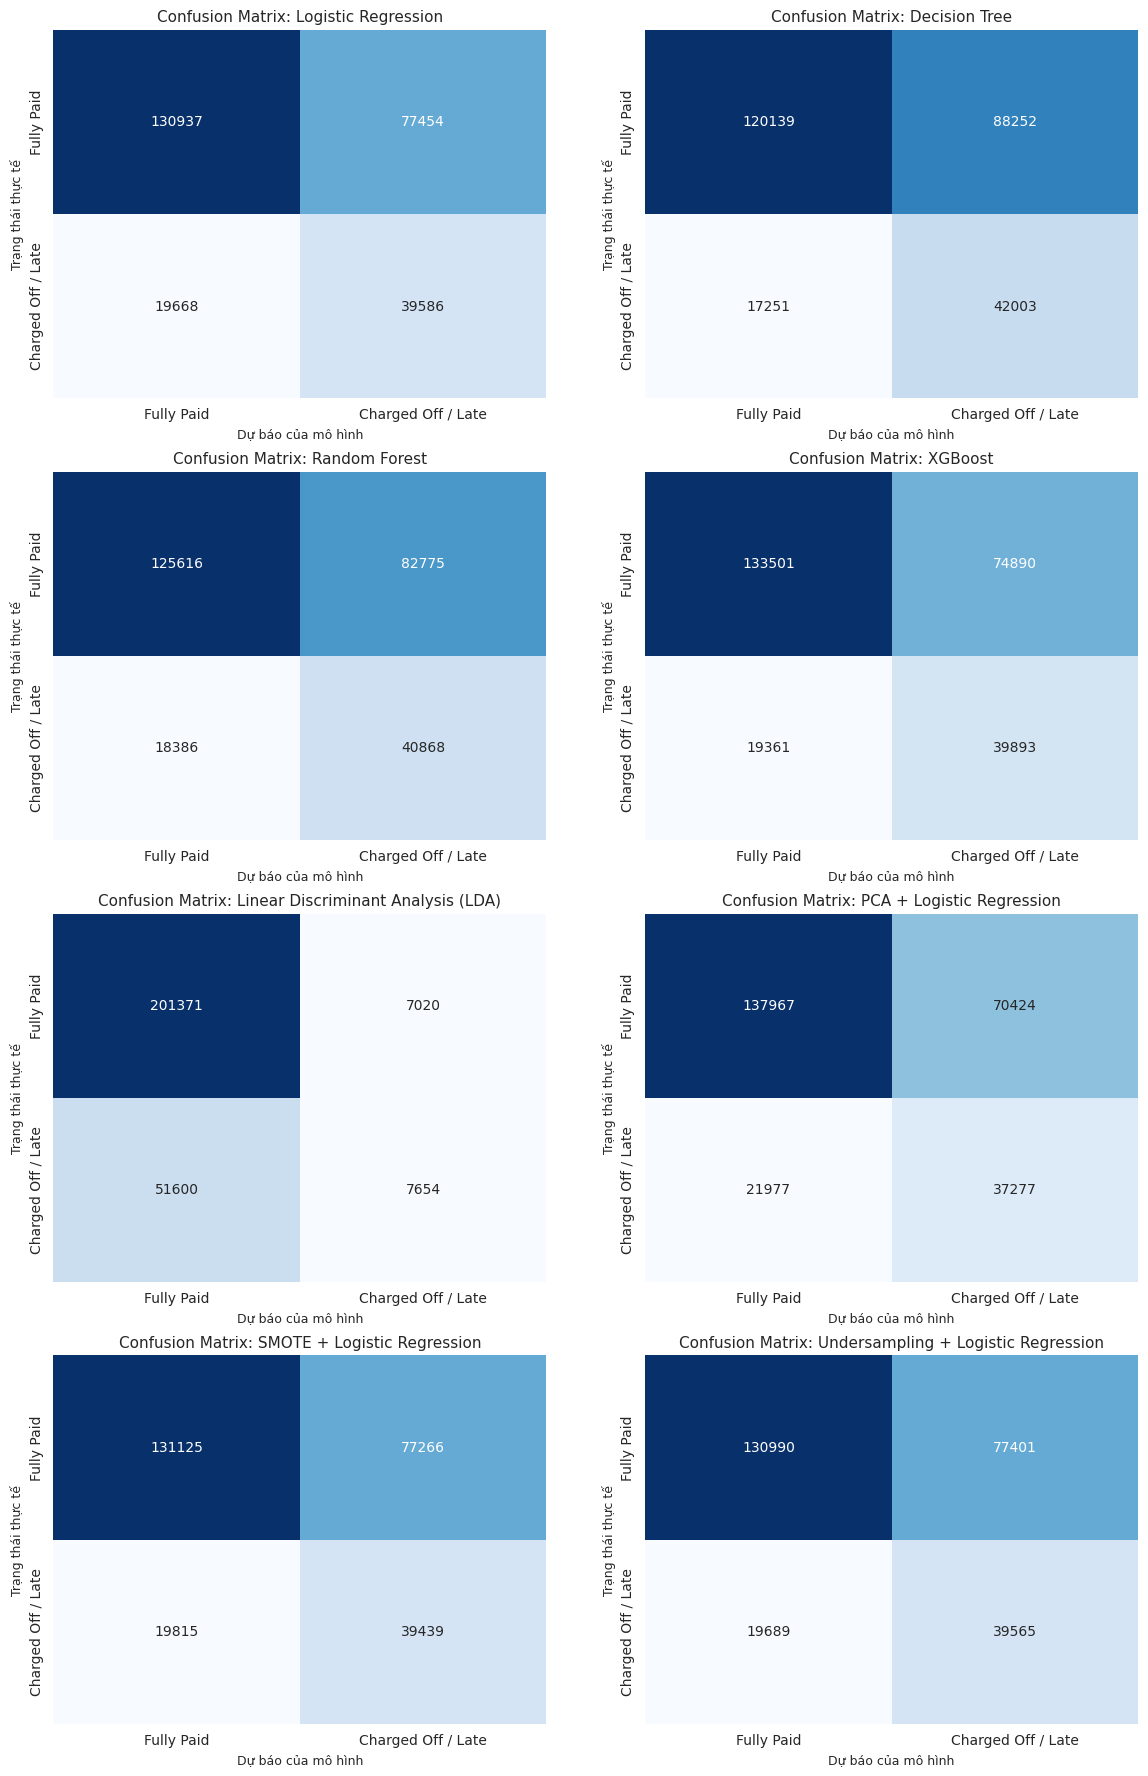

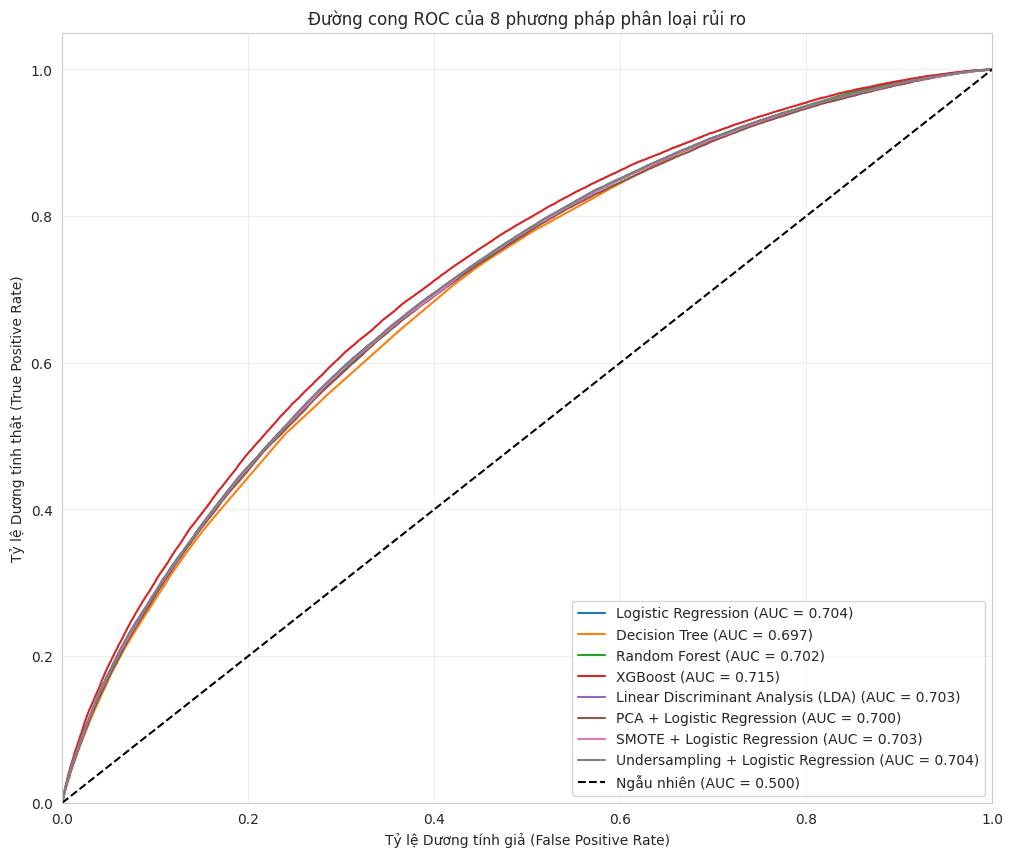

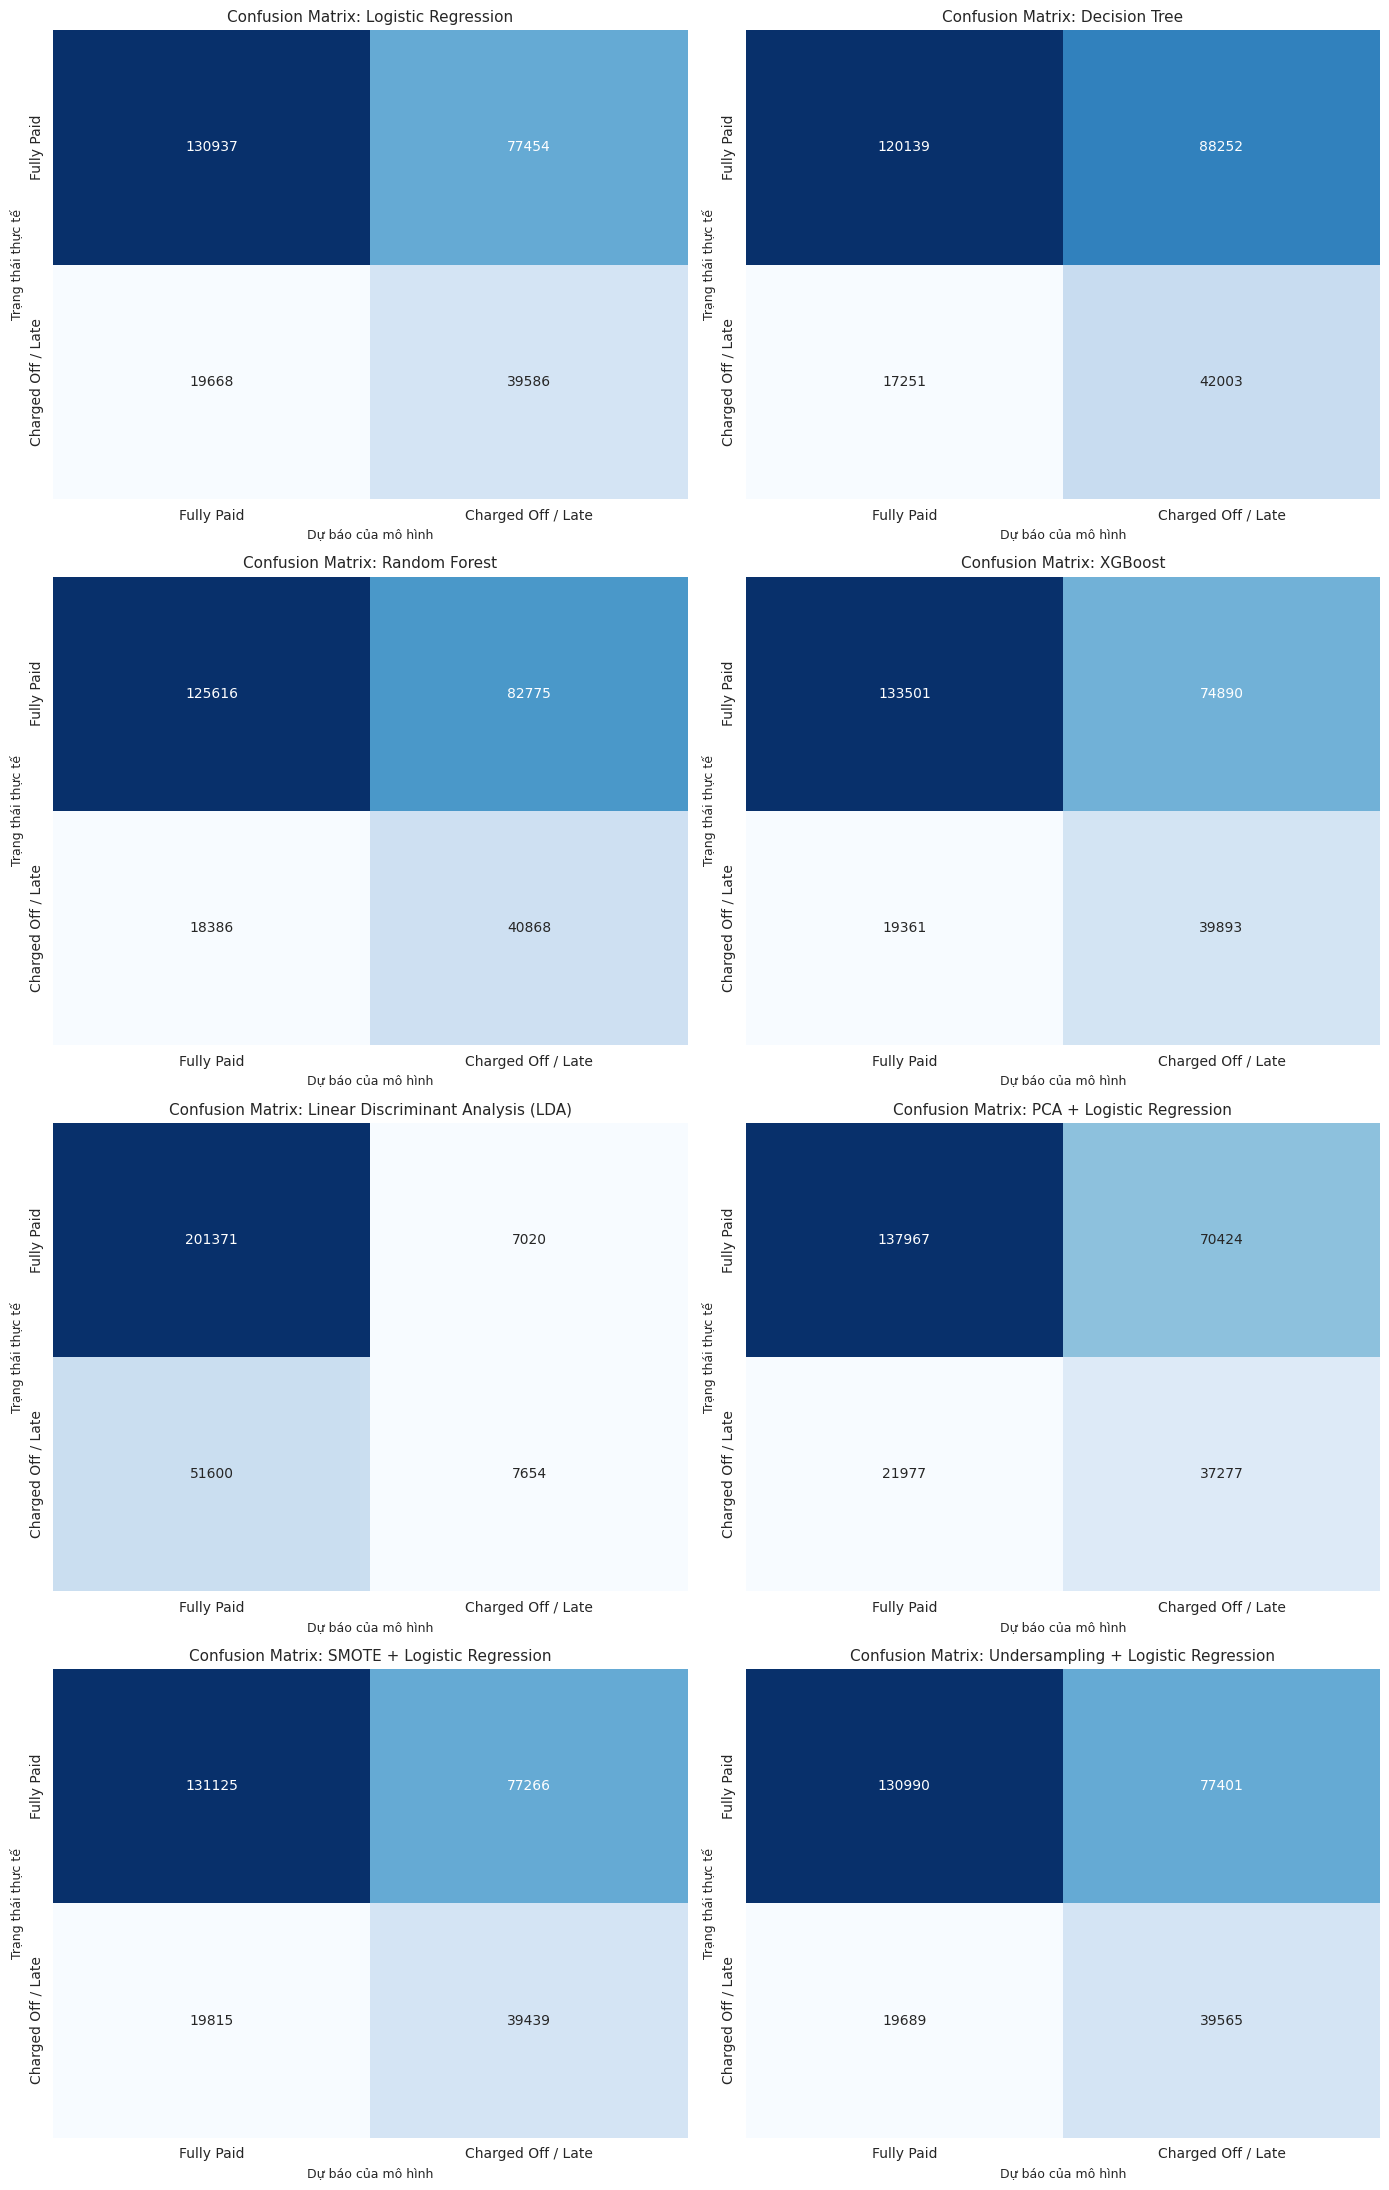

,Mô hình,Accuracy,Precision,Recall (Nhạy),F1-Score,ROC-AUC,CV ROC-AUC (Mean)
0,Logistic Regression,0.6371,0.3382,0.6681,0.4491,0.7041,0.704515
1,Decision Tree,0.6058,0.3225,0.7089,0.4433,0.6971,0.697797
2,Random Forest,0.6220,0.3305,0.6897,0.4469,0.7024,0.703107
3,XGBoost,0.6479,0.3476,0.6733,0.4584,0.7153,0.715284
4,Linear Discriminant Analysis (LDA),0.7810,0.5216,0.1292,0.2071,0.7028,0.703482
5,PCA + Logistic Regression,0.6548,0.3461,0.6291,0.4466,0.7001,0.700702
6,SMOTE + Logistic Regression,0.6373,0.3379,0.6656,0.4483,0.7031,N/A
7,Undersampling + Logistic Regression,0.6372,0.3383,0.6677,0.4490,0.7042,N/A


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Cấu hình đánh giá cho từng mô hình
eval_configs = [
    {'name': 'Logistic Regression', 'model': lr_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': True},
    {'name': 'Decision Tree', 'model': dt_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': True},
    {'name': 'Random Forest', 'model': rf_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': True},
    {'name': 'XGBoost', 'model': xgb_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': True},
    {'name': 'Linear Discriminant Analysis (LDA)', 'model': lda_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': True},
    {'name': 'PCA + Logistic Regression', 'model': pca_lr_model, 'X_test': X_test_pca, 'X_train': X_train_pca, 'has_cv': True},
    {'name': 'SMOTE + Logistic Regression', 'model': smote_lr_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': False},
    {'name': 'Undersampling + Logistic Regression', 'model': under_lr_model, 'X_test': X_test_scaled, 'X_train': X_train_scaled, 'has_cv': False}
]

results = []

# Thiết lập khung vẽ Confusion Matrix của cả 8 mô hình (Lưới 4x2)
fig, axes = plt.subplots(4, 2, figsize=(14, 22))
axes = axes.ravel()

plt_roc = plt.figure(figsize=(12, 10))
ax_roc = plt_roc.add_subplot(111)

for idx, config in enumerate(eval_configs):
    name = config['name']
    model = config['model']
    X_t = config['X_test']

    # Dự đoán
    y_pred = model.predict(X_t)
    y_proba = model.predict_proba(X_t)[:, 1]

    # Tính toán các chỉ số
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    # Đánh giá chéo Cross-Validation (CV) cho các mô hình không đổi kích thước mẫu để tránh rò rỉ dữ liệu
    cv_mean = None
    if config['has_cv']:
        print(f"Đang thực hiện Cross-Validation cho {name}...")
        try:
            cv_scores = cross_val_score(model, config['X_train'], y_train, cv=3, scoring='roc_auc', n_jobs=-1)
            cv_mean = cv_scores.mean()
        except Exception as e:
            cv_mean = None

    results.append({
        'Mô hình': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Nhạy)': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'CV ROC-AUC (Mean)': cv_mean if cv_mean is not None else "N/A"
    })

    # Vẽ ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

    # Vẽ Confusion Matrix dạng Heatmap
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Fully Paid', 'Charged Off / Late'], yticklabels=['Fully Paid', 'Charged Off / Late'])
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=11)
    axes[idx].set_xlabel("Dự báo của mô hình", fontsize=9)
    axes[idx].set_ylabel("Trạng thái thực tế", fontsize=9)

# Trực quan hóa ROC Curve
ax_roc.plot([0, 1], [0, 1], 'k--', label='Ngẫu nhiên (AUC = 0.500)')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('Tỷ lệ Dương tính giả (False Positive Rate)')
ax_roc.set_ylabel('Tỷ lệ Dương tính thật (True Positive Rate)')
ax_roc.set_title('Đường cong ROC của 8 phương pháp phân loại rủi ro')
ax_roc.legend(loc="lower right")
ax_roc.grid(alpha=0.3)

# Hiển thị biểu đồ ROC
plt.figure(plt_roc.number)
plt.show()

# Hiển thị biểu đồ Confusion Matrices
fig.tight_layout()
display(fig)
plt.close(fig)

# Hiển thị kết quả dạng bảng so sánh
df_results = pd.DataFrame(results)
display(df_results.round(4))


## Bảng so sánh mô hình và Nhận xét (0.7 điểm)



Dưới đây là bảng tổng hợp các chỉ số hiệu năng thực tế thu được sau khi huấn luyện và kiểm thử 8 phương án trên tập dữ liệu đã tích hợp các khoản vay trễ hạn (`Late`):


| **STT** | **Phương án / Mô hình**                 | **Accuracy** | **Precision (Nhãn 1)** | **Recall (Nhãn 1)** | **F1-Score (Nhãn 1)** | **ROC-AUC** |
| :-----: | :-------------------------------------- | -----------: | ---------------------: | ------------------: | --------------------: | ----------: |
|    1    | **Logistic Regression (Baseline)**      |       63,71% |                 33,82% |              66,81% |                44,91% |   **0,704** |
|    2    | **Decision Tree**                       |       60,58% |                 32,25% |          **70,89%** |                44,33% |       0,697 |
|    3    | **Random Forest**                       |       62,20% |                 33,05% |              68,97% |                44,69% |       0,702 |
|    4    | **XGBoost Classifier**                  |       64,79% |                 34,76% |              67,33% |            **45,85%** |   **0,715** |
|    5    | **LDA (Linear Discriminant Analysis)**  |   **78,10%** |             **52,16%** |              12,92% |                20,71% |       0,703 |
|    6    | **PCA + Logistic Regression**           |       65,48% |                 34,61% |              62,91% |                44,66% |       0,700 |
|    7    | **SMOTE + Logistic Regression**         |       63,73% |                 33,79% |              66,56% |                44,82% |       0,703 |
|    8    | **Undersampling + Logistic Regression** |       63,72% |                 33,83% |              66,77% |                44,90% |       0,704 |




1. **Mô hình tốt nhất toàn diện (XGBoost):**

   * **XGBoost Classifier** đạt chỉ số phân tách rủi ro tốt nhất với **ROC-AUC = 0.715** và **F1-Score = 45.85%** cao nhất trong toàn bộ các mô hình. Điều này chứng tỏ thuật toán Boosting có khả năng tối ưu hóa phi tuyến tính vượt trội trên tập dữ liệu Lending Club có số lượng đặc trưng lớn.



2. **Hiện tượng đặc biệt của LDA (Linear Discriminant Analysis):**

   * LDA đạt **Accuracy = 78.10%** và **Precision = 52.16%** cao nhất, nhưng chỉ số **Recall cực kỳ thấp (12.92%)**.

   * *Giải thích:* Do LDA không có cơ chế tự động cân bằng nhãn (class weight) và giả định dữ liệu phân phối chuẩn đa biến không hoàn toàn được thỏa mãn. Mô hình có xu hướng dự báo phần lớn khách hàng là "Fully Paid" để đạt độ chính xác cao. Điều này chứng minh rằng **Accuracy là chỉ số vô nghĩa khi đánh giá bài toán mất cân bằng nhãn**, vì ngân hàng sẽ bỏ lọt tới hơn 87% khách hàng nợ xấu.



3. **Sự tương đồng giữa các phương pháp cân bằng dữ liệu (SMOTE, Undersampling, Class Weight):**

   * Mô hình **Logistic Regression Baseline (dùng class_weight='balanced')**, **SMOTE + LR** và **Undersampling + LR** cho kết quả gần như trùng khớp hoàn toàn (Recall quanh mức 66-67%, Precision quanh mức 33.8% và ROC-AUC = 0.703 - 0.704).

   * *Giải thích ý nghĩa khoa học:* Việc phạt trọng số hàm mất mát (`class_weight`), tạo mẫu nhân tạo (`SMOTE`) hay giảm mẫu đa số (`Undersampling`) về mặt lý thuyết đều hướng tới việc điều chỉnh ranh giới phân loại của mô hình tuyến tính về tỷ lệ 50:50. Tuy nhiên, việc sử dụng `class_weight='balanced'` trực tiếp trên mô hình là giải pháp tối ưu nhất vì **không phát sinh chi phí tính toán tạo mẫu ảo (SMOTE) hay làm mất thông tin hữu ích (Undersampling)**.



4. **Kỹ thuật giảm chiều dữ liệu PCA:**

   * **PCA + Logistic Regression** giữ được hiệu năng phân tách ổn định (**ROC-AUC = 0.700**) dù chỉ sử dụng 10 thành phần chính (thay vì hơn 80 đặc trưng ban đầu). Đây là minh chứng cho thấy PCA đã loại bỏ tốt các biến đa cộng tuyến và giữ lại hầu hết thông tin cốt lõi của hồ sơ khách hàng vay.



### **Khuyến nghị kinh doanh cho ngân hàng:**

* Nếu ngân hàng đặt mục tiêu **tối đa hóa lợi nhuận và phê duyệt tự động chính xác**: Nên triển khai **XGBoost Classifier** để có độ chính xác và khả năng lọc rủi ro cân bằng tốt nhất.

* Nếu ngân hàng ưu tiên **phòng ngừa rủi ro mất vốn tuyệt đối** (chấp nhận từ chối nhầm khách hàng tốt để không bị nợ xấu): Nên sử dụng **Decision Tree** (chỉ số **Recall cao nhất = 70.89%**) hoặc **Logistic Regression (Baseline/SMOTE)** làm bộ quy tắc duyệt tín dụng.


# C. Diễn giải kết quả & Đề xuất (2.5 điểm)

## C1. Diễn giải kết quả theo ngôn ngữ kinh doanh (1.0 điểm)

* **Tên bước (Name):** Phân tích ý nghĩa kết quả mô hình đối với hoạt động kinh doanh tín dụng.
* **Mục đích (Purpose):** Dịch các chỉ số toán học (Precision, Recall) thành các con số tài chính có nghĩa để ban giám đốc ngân hàng đưa ra quyết định.
* **Phương pháp (Method):** Giải thích ý nghĩa của lỗi loại 1 (False Positive) và lỗi loại 2 (False Negative):
  - **Lỗi loại 2 (False Negative - Bỏ sót nợ xấu):** Mô hình dự đoán khách hàng an toàn nhưng thực tế họ vỡ nợ. Lỗi này làm ngân hàng mất trắng toàn bộ số tiền giải ngân gốc (rủi ro cao nhất).
  - **Lỗi loại 1 (False Positive - Từ chối nhầm khách tốt):** Mô hình dự đoán khách hàng sẽ vỡ nợ nhưng thực tế họ có khả năng trả. Lỗi này làm ngân hàng mất đi cơ hội kinh doanh (chi phí cơ hội) và doanh thu lãi suất.
  - **Mức độ quan trọng của đặc trưng (Feature Importance):** Dùng Feature Importance để xác định các chỉ số tài chính của khách hàng đi vay ảnh hưởng mạnh nhất tới khả năng trả nợ.
* **Phản hồi mong đợi (Expected Outcome):** Biểu đồ Feature Importance hiển thị các cột quan trọng nhất và các nhận định kinh doanh sâu sắc.


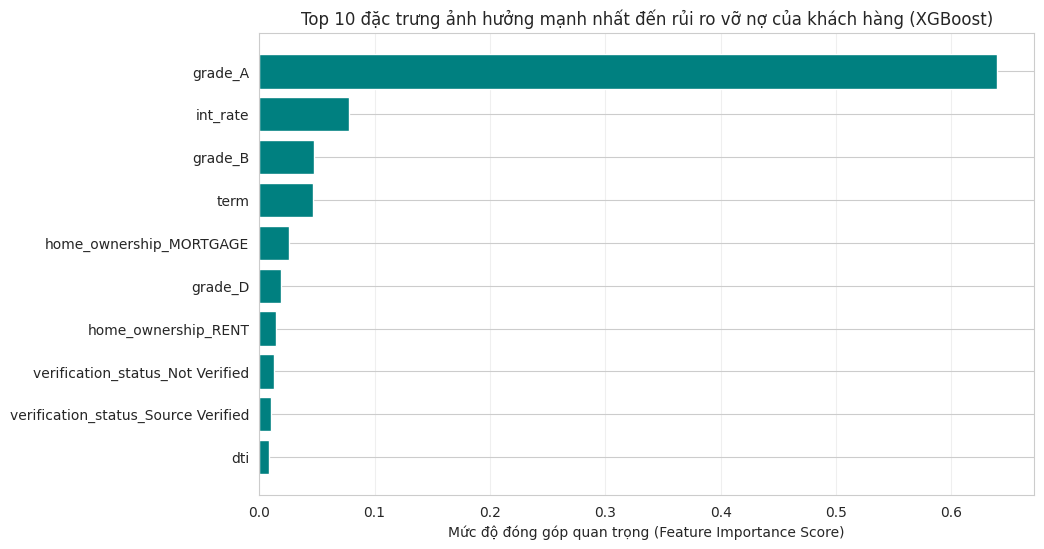

✅ Hoàn thành phân tích Feature Importance.


In [ ]:
# Vẽ Feature Importance từ mô hình XGBoost hoặc Random Forest
import numpy as np
import matplotlib.pyplot as plt

importances = xgb_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Lấy Top 10 đặc trưng quan trọng nhất
top_k = 10
top_indices = indices[:top_k]
top_importances = importances[top_indices]
top_names = [feature_names[i] for i in top_indices]

plt.figure(figsize=(10, 6))
plt.barh(range(top_k), top_importances[::-1], align='center', color='teal')
plt.yticks(range(top_k), top_names[::-1])
plt.xlabel('Mức độ đóng góp quan trọng (Feature Importance Score)')
plt.title('Top 10 đặc trưng ảnh hưởng mạnh nhất đến rủi ro vỡ nợ của khách hàng (XGBoost)')
plt.grid(axis='x', alpha=0.3)
plt.show()

print("✅ Hoàn thành phân tích Feature Importance.")


### **Nhận xét Insight Kinh doanh từ Mô hình:**
1. **Hạng tín dụng tốt (`grade_A` và `grade_B`):** Là các nhân tố quyết định mạnh nhất đến khả năng dự báo của mô hình (đặc biệt là `grade_A` đứng vị trí số 1 với mức độ đóng góp vượt trội > 60%). Điều này chứng tỏ việc xác định một khách hàng thuộc nhóm an toàn nhất (Grade A) có ý nghĩa quyết định đối với hệ thống phê duyệt rủi ro của Lending Club.
2. **Lãi suất (`int_rate`):** Đứng vị trí thứ hai về tầm quan trọng (gần 8%). Lãi suất cao trực tiếp làm tăng gánh nặng tài chính định kỳ, là nguyên nhân hàng đầu dẫn đến việc khách hàng mất khả năng thanh toán.
3. **Kỳ hạn khoản vay (`term`):** Đứng vị trí thứ tư (gần 5%). Việc khách hàng lựa chọn kỳ hạn vay dài (60 tháng) mang lại rủi ro tiềm ẩn cao hơn so với kỳ hạn ngắn (36 tháng) do biến số thời gian dài khó lường hơn.
4. **Tình trạng sở hữu nhà ở (`home_ownership_MORTGAGE` và `home_ownership_RENT`):** Nằm trong top 7 đặc trưng quan trọng nhất. Điều này cho thấy tình trạng nhà ở (có nhà thế chấp hay đang ở nhà thuê) phản ánh gián tiếp sự ổn định cuộc sống và tác động mạnh đến hành vi trả nợ thực tế của người đi vay.
5. **Trạng thái xác thực thu nhập (`verification_status`) & Tỷ lệ nợ (`dti`):** Tuy nằm ở cuối nhóm top 10 nhưng vẫn là các chỉ báo định lượng quan trọng bổ trợ cho quyết định phân loại rủi ro của mô hình.

## C2. Đề xuất hành động kinh doanh thực tế (1.0 điểm)

Dựa trên kết quả phân tích tầm quan trọng của các đặc trưng (Feature Importance) từ mô hình XGBoost tối ưu ở trên, nhóm đề xuất các hành động kinh doanh cụ thể cho ngân hàng như sau:

### **1. Đề xuất ngắn hạn (Chính sách phê duyệt & Tối ưu quy trình)**
- **Ưu tiên phê duyệt tự động nhanh (Green Channel) cho nhóm Grade A và B:** Vì `grade_A` và `grade_B` có sức mạnh phân loại lớn nhất để xác định khách hàng tốt, ngân hàng nên thiết lập luồng phê duyệt tự động siêu tốc cho nhóm này nhằm tối ưu hóa trải nghiệm khách hàng tốt và cắt giảm chi phí vận hành thẩm định.
- **Định giá dựa trên rủi ro (Risk-Based Pricing) theo lãi suất (`int_rate`):** Do lãi suất là biến rủi ro hàng đầu, cần áp dụng mức lãi suất biên chiết khấu cho nhóm khách hàng có điểm tín dụng cao để giữ chân họ, đồng thời áp lãi suất cao hơn đối với nhóm rủi ro trung bình để bù đắp tỷ lệ tổn thất kỳ vọng.
- **Hạn chế kỳ hạn dài (`term` = 60 tháng) đối với khách hàng nhóm dưới:** Chỉ phê duyệt kỳ hạn 36 tháng cho các khách hàng thuộc phân khúc rủi ro trung bình để giảm thời gian phơi nhiễm rủi ro dòng tiền.

### **2. Đề xuất dài hạn (Xây dựng hệ thống Scorecard)**
- **Trọng dụng biến sở hữu nhà ở (`home_ownership`):** Vì tình trạng nhà ở có mức độ ảnh hưởng vượt trội cả biến tài chính `dti` trong mô hình XGBoost, ngân hàng bắt buộc phải đưa thuộc tính sở hữu nhà đất thành một điều kiện điểm cộng quan trọng trong hệ thống chấm điểm tín dụng (Scorecard) nội bộ.
- **Tích hợp mô hình vào hệ thống phê duyệt tự động (Auto-decisioning):** Sử dụng điểm xác suất vỡ nợ từ mô hình XGBoost làm điểm số Credit Score của khách hàng nộp hồ sơ. Thiết lập ngưỡng cắt (Cut-off Score) để tự động duyệt, từ chối, hoặc chuyển sang thẩm định thủ công.

## C3. Giới hạn mô hình và Hướng phát triển tương lai (0.5 điểm)

### **1. Giới hạn của mô hình hiện tại**
- **Mất cân bằng nhãn (Class Imbalance):** Bộ dữ liệu Lending Club có số lượng khoản vay tất toán (`Fully Paid`) vượt trội so với nợ xấu (`Charged Off`). Dù mô hình đã áp dụng kỹ thuật gán trọng số lớp (`class_weight='balanced'`), độ chính xác của việc dự báo nhãn nợ xấu vẫn bị ảnh hưởng.
- **Thiếu biến số vĩ mô:** Mô hình hiện tại chỉ sử dụng các đặc trưng nội tại của khách hàng. Trong thực tế, khả năng vỡ nợ chịu tác động mạnh bởi các yếu tố kinh tế vĩ mô (như lạm phát, tỷ lệ thất nghiệp, lãi suất ngân hàng trung ương).
- **Dữ liệu tĩnh:** Mô hình được huấn luyện trên dữ liệu tĩnh tại một thời điểm, chưa cập nhật được hành vi thay đổi theo thời gian của khách hàng.

### **2. Hướng phát triển trong tương lai**
- **Ứng dụng mô hình Deep Learning:** Thử nghiệm các kiến trúc mạng nơ-ron nhân tạo nâng cao để trích xuất các đặc trưng phi tuyến sâu hơn.
- **Tích hợp nguồn dữ liệu thay thế (Alternative Data):** Bổ sung các thông tin phi truyền thống như lịch sử thanh toán hóa đơn điện nước, hành vi mua sắm thương mại điện tử, mạng xã hội để đánh giá khách hàng chưa có lịch sử tín dụng.
- **Ứng dụng mô hình học sâu chuyên biệt cho dữ liệu bảng:** Thử nghiệm các mô hình như TabNet, hoặc các kỹ thuật Generative Adversarial Networks (GANs) nâng cao để tạo ra các mẫu thiểu số (nợ xấu) nhân tạo chất lượng cao hơn SMOTE.


# D. Báo cáo & Slide Trình bày (2.0 điểm)

## D1. Cấu trúc Notebook (0.6 điểm)
Notebook này được xây dựng hoàn toàn từ đầu, phân bổ rõ ràng thành 8 phần tiêu chuẩn, kết hợp nhuần nhuyễn giữa Markdown giải thích chi tiết và các Code cell sạch, có comment rõ ràng. Notebook chạy thành công từ đầu đến cuối mà không gặp lỗi.

## D2. Slide Trình bày tóm tắt (0.5 điểm)

Dưới đây là dàn trang tóm tắt nội dung slide báo cáo đồ án (khoảng 10 slides chuẩn):

| Slide | Tiêu đề | Nội dung chính | Biểu đồ minh họa |
| :--- | :--- | :--- | :--- |
| **1** | Giới thiệu Đề tài | Tên dự án: Phân loại rủi ro tín dụng; Thành viên nhóm | Hình ảnh minh họa dự án |
| **2** | Tổng quan Bài toán | Động cơ kinh doanh, bài toán nợ xấu và vai trò của học máy | Sơ đồ quy trình cho vay |
| **3** | Mô tả Dữ liệu | Lending Club Dataset: 2.2 triệu dòng, 145 đặc trưng số & chữ | Bảng thống kê mô tả đặc trưng |
| **4** | Phân tích EDA | Các phát hiện chính về phân bố số tiền vay, thu nhập, DTI | Boxplot, Histogram phân phối |
| **5** | Khảo sát Rủi ro | Mối quan hệ giữa hạng tín dụng (Grade) và tỷ lệ vỡ nợ thực tế | Barplot tỷ lệ nợ xấu theo Grade |
| **6** | Tiền xử lý dữ liệu | Xử lý khuyết thiếu, loại bỏ cột rò rỉ (Leakage) có bằng chứng | Sơ đồ xử lý khuyết thiếu/leakage |
| **7** | Thiết lập Mô hình | Chia dữ liệu Train-Test chống Leakage; 8 phương pháp (LR, DT, RF, XGBoost, LDA, PCA, SMOTE, Undersampling) | Sơ đồ chia dữ liệu và chuẩn hóa |
| **8** | Kết quả Mô hình | So sánh hiệu năng Accuracy, Precision, Recall, ROC-AUC | Biểu đồ đường cong ROC Curve |
| **9** | Đề xuất Kinh doanh | Các khuyến nghị ngắn hạn (chặn DTI, hạn chế hạn mức) và dài hạn | Biểu đồ Feature Importance |
| **10** | Kết luận & Hạn chế | Điểm mạnh của đồ án, giới hạn RAM vĩ mô và hướng phát triển | Hướng ứng dụng học sâu (TabNet) & Dữ liệu vĩ mô |
